Here is outline of this notebook
Part 1
Healthcare Data Silos
(Create synthetic hospital systems)

Part 2
Data Exploration

Part 3
Data Quality Problems

Part 4
Data Cleaning

Part 5
Data Validation

Part 6
Data Harmonization

Part 7
Master Patient Index (MPI)

Part 8
Timeline Alignment

Part 9
Episode Construction

Part 10
Index Date

Part 11
Lookback Window

Part 12
Prediction Window

Part 13
Risk Period

Part 14
HIPAA De-identification

Part 15
Feature Engineering



What makes this different?

Instead of using one CSV,

we'll create five independent hospital systems.

Hospital

        ┌──────────────┐
        │     EHR      │
        └──────────────┘

        ┌──────────────┐
        │ Laboratory   │
        └──────────────┘

        ┌──────────────┐
        │ Pharmacy     │
        └──────────────┘

        ┌──────────────┐
        │ Billing      │
        └──────────────┘

        ┌──────────────┐
        │ Demographics │
        └──────────────┘

The Synthetic Hospital

We'll create about 100 patients.

Each patient will have

demographics
doctor visits
diagnoses
lab tests
medications
insurance claims

We'll intentionally create problems like

✅ Missing IDs

✅ Duplicate patients

✅ Different lab units

✅ Different diagnosis names

✅ Wrong dates

Exactly like real hospital data.

Then we'll purposely "break" the data.

For example,

Patient Registry

P001

John Smith

EHR

P001

John A Smith

Lab

Patient ID missing

Billing

Type II Diabetes

Another hospital

Diabetes Mellitus

Now we have a real healthcare integration problem.

Then we'll fix everything exactly like healthcare data engineers do.

Rather than generating random synthetic data, we'll generate realistic patient journeys.

Patient P001

Jan 2
↓

Primary Care Visit

↓

Doctor diagnoses diabetes

↓

Jan 3

HbA1c ordered

↓

Jan 4

HbA1c = 8.9%

↓

Jan 5

Metformin prescribed

↓

March 15

Follow-up visit

↓

June 10

Hospital admission

↓

June 14

Discharge

↓

July 5

Readmitted


This creates realistic timelines that make later sections (episode construction, lookback windows, feature engineering, and machine learning) much more meaningful.

Part 1 — Building a Synthetic Hospital System
Real Hospital Scenario

Imagine you are a Data Engineer at ABC Healthcare Network.

               ABC Healthcare Network

          ┌──────────────────────────┐
          │  Patient Registration     │
          └──────────────────────────┘

          ┌──────────────────────────┐
          │         EHR              │
          └──────────────────────────┘

          ┌──────────────────────────┐
          │     Laboratory (LIS)     │
          └──────────────────────────┘

          ┌──────────────────────────┐
          │      Pharmacy            │
          └──────────────────────────┘

          ┌──────────────────────────┐
          │ Billing / Claims System  │
          └──────────────────────────┘


Each department stores its own data.

No department shares the same database.

Your job is to combine everything into one analytics-ready dataset.

Why do we create separate datasets?

Hospitals rarely store everything in one table.
Registration
      ↓
Stores Patient Information

EHR
      ↓
Stores Doctor Visits

Laboratory
      ↓
Stores Lab Results

Pharmacy
      ↓
Stores Medications

Billing
      ↓
Stores Claims


Notebook Goal

By the end of this notebook we'll transform

5 Separate Systems

↓

Cleaning

↓

Validation

↓

Harmonization

↓

Patient Timeline

↓

Episodes

↓

Feature Engineering

↓

Machine Learning Dataset



Step 1 — Import Libraries
What does this code do?

Every notebook starts by importing Python libraries.

Think of libraries as toolboxes.

Each toolbox has a different job.

In [1]:
import pandas as pd
import numpy as np
import random

from datetime import datetime, timedelta

# Make random data reproducible
random.seed(42)
np.random.seed(42)

Why do we set the random seed?

Without it,

every notebook run generates different patients.

Step 2 — Create Basic Hospital Information
What does this code do?

Before generating patient data,

we first create dictionaries containing common healthcare values.



Instead of typing
Male
Female

100 times,

we store them once.

The same applies to

diagnoses
medications
providers
hospitals

This makes the code cleaner and easier to update.

In [2]:
first_names = [
    "John","Sarah","David","Emma","Michael",
    "Sophia","James","Olivia","Daniel","Emily"
]

last_names = [
    "Smith","Johnson","Brown","Williams",
    "Jones","Garcia","Miller","Davis"
]

genders = [
    "Male",
    "Female"
]

cities = [
    "Chicago",
    "Boston",
    "Seattle",
    "Houston",
    "Phoenix"
]

providers = [
    "Dr. Adams",
    "Dr. Lee",
    "Dr. Wilson",
    "Dr. Patel"
]

hospitals = [
    "Central Hospital",
    "North Medical Center",
    "City Health Clinic"
]

Diagnosis List

We'll purposely include diseases that are common in analytics projects.

In [3]:
diagnoses = [
    "Type 2 Diabetes",
    "Hypertension",
    "Heart Failure",
    "COPD",
    "Pneumonia",
    "Asthma"
]

Laboratory Tests

In [4]:
lab_tests = [
    "HbA1c",
    "Glucose",
    "CBC",
    "Troponin",
    "Creatinine"
]

Medications

In [5]:
medications = [
    "Metformin",
    "Lisinopril",
    "Aspirin",
    "Atorvastatin",
    "Insulin"
]

Billing Codes (Simplified)

In [6]:
icd_codes = {
    "Type 2 Diabetes":"E11",
    "Hypertension":"I10",
    "Heart Failure":"I50",
    "COPD":"J44",
    "Pneumonia":"J18",
    "Asthma":"J45"
}

cpt_codes = [
    "80053",
    "83036",
    "93000",
    "71045",
    "99213"
]

Why do healthcare engineers create these lists?

Instead of writing

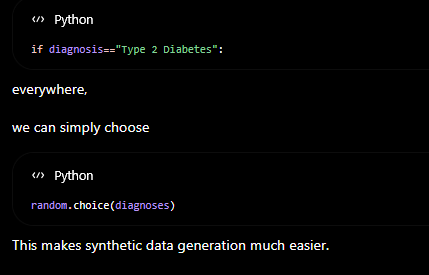

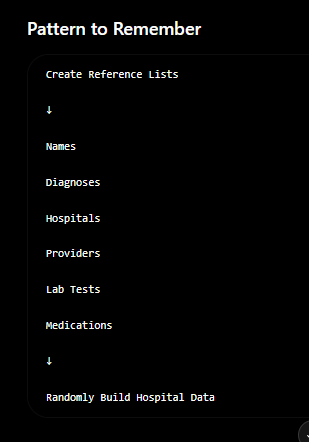

Step 3 — Decide How Many Patients to Generate
What does this code do?

Now we decide the size of our synthetic hospital.

In real hospitals this might be millions of patients.

For learning purposes, we'll create a manageable dataset.

In [7]:
NUM_PATIENTS = 100

Later, every system (EHR, Lab, Pharmacy, Billing) will use these same patient IDs.

Example:

Patient Registry

P001
P002
P003
...
P100

This creates a consistent foundation that lets us later demonstrate missing IDs, duplicates, harmonization, and patient matching.

Pattern to remember




Reference Lists
        ↓
Define Dataset Size
        ↓
Generate Patient Registry
        ↓
Generate EHR
        ↓
Generate Lab
        ↓
Generate Pharmacy
        ↓
Generate Billing

Part 1 — Section 4: Build the Patient Registration System

Real Hospital Scenario

Imagine a patient walks into the hospital for the first time.

The Registration Department creates a patient profile.

They collect:

Patient ID
Name
Date of Birth
Gender
City

This information becomes the Master Patient Record.

Every department later refers to this patient.

Patient Registration
        │
        ▼
Patient ID = P001
        │
        ▼
EHR
Lab
Pharmacy
Billing

Notice:

The Registration department does NOT store diagnoses or lab results.

It only stores patient identit

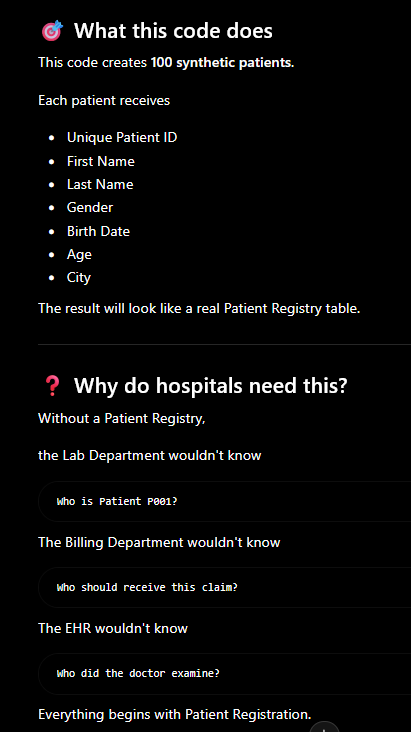

In [8]:
patients = []

for i in range(1, NUM_PATIENTS + 1):

    patient_id = f"P{i:03d}"

    first_name = random.choice(first_names)

    last_name = random.choice(last_names)

    gender = random.choice(genders)

    city = random.choice(cities)

    # Random birth date between 1945 and 2005
    birth_date = datetime(
        random.randint(1945, 2005),
        random.randint(1, 12),
        random.randint(1, 28)
    )

    age = (datetime.today() - birth_date).days // 365

    patients.append({

        "patient_id": patient_id,

        "first_name": first_name,

        "last_name": last_name,

        "gender": gender,

        "birth_date": birth_date.date(),

        "age": age,

        "city": city

    })

patient_df = pd.DataFrame(patients)

View the Dataset

In [9]:
patient_df.head()

,patient_id,first_name,last_name,gender,birth_date,age,city
0,P001,Sarah,Smith,Female,1959-03-24,67,Boston
1,P002,Sarah,Johnson,Female,1946-02-07,80,Chicago
2,P003,Emma,Smith,Male,1971-04-15,55,Phoenix
3,P004,Emily,Jones,Male,1989-07-11,37,Boston
4,P005,Michael,Brown,Male,1951-02-13,75,Seattle


In [10]:
patient_df.shape


(100, 7)

In [11]:
patient_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   patient_id  100 non-null    object
 1   first_name  100 non-null    object
 2   last_name   100 non-null    object
 3   gender      100 non-null    object
 4   birth_date  100 non-null    object
 5   age         100 non-null    int64 
 6   city        100 non-null    object
dtypes: int64(1), object(6)
memory usage: 5.6+ KB


This tells us

Any missing values?
Column data types?
Number of rows?

Healthcare engineers always inspect this before moving forwa

Summary Statistics

In [12]:
patient_df.describe(include="all")

,patient_id,first_name,last_name,gender,birth_date,age,city
count,100,100,100,100,100,100.000000,100
unique,100,10,8,2,100,NaN,5
top,P001,James,Smith,Male,1959-03-24,NaN,Boston
freq,1,14,17,52,1,NaN,24
mean,NaN,NaN,NaN,NaN,NaN,51.490000,NaN
std,NaN,NaN,NaN,NaN,NaN,17.724317,NaN
min,NaN,NaN,NaN,NaN,NaN,20.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,37.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,52.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,67.000000,NaN


Useful for

Average age
Most common city
Most common gender

Create Empty List
        ↓
Loop Through Patients
        ↓
Generate Random Values
        ↓
Store as Dictionary
        ↓
Append to List
        ↓
Convert List → DataFrame
        ↓
Explore the DataFrame

Part 1 — Section 5: Build the Electronic Health Record (EHR)

Real Hospital Scenario

Yesterday, we created our Patient Registry.

That registry only tells us who the patient is.

Now imagine John visits the hospital.

The doctor opens the Electronic Health Record (EHR) and documents:

Why the patient came
Diagnosis
Blood Pressure
Heart Rate
Which doctor treated them
Which hospital they visited
Whether they were admitted or discharged

This information is stored inside the EHR system.

Patient Registry
        │
        ▼
Patient P001

        ▼

Hospital Visit

        ▼

Doctor Examination

        ▼

EHR Record Created

Notice something important:

One patient can visit the hospital many times.

So the relationship becomes:

One Patient
      │
      ├──────── Visit 1
      ├──────── Visit 2
      ├──────── Visit 3
      └──────── Visit 4

This is called a One-to-Many Relationship.

One patient → Many encounters.

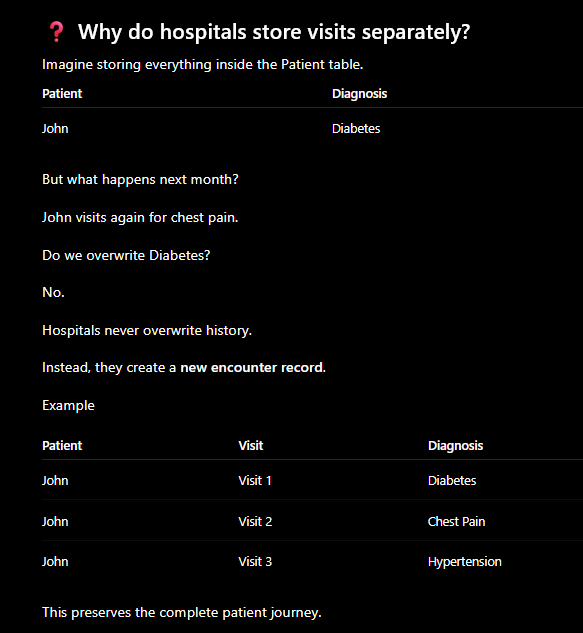

In [13]:
!pip install faker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 17.7 MB/s eta 0:00:00


In [14]:
from faker import Faker

fakery = Faker()

diagnoses = [
    "Hypertension",
    "Type 2 Diabetes",
    "Asthma",
    "Heart Failure",
    "Pneumonia",
    "Chest Pain",
    "COPD",
    "Kidney Disease"
]

admission_types = [
    "Emergency",
    "Outpatient",
    "Inpatient"
]

hospitals = [
    "City Hospital",
    "General Hospital",
    "Regional Medical Center"
]

doctors = [
    "Dr. Smith",
    "Dr. Brown",
    "Dr. Lee",
    "Dr. Wilson",
    "Dr. Davis"
]

ehr_records = []

visit_counter = 1

for patient in patient_df["patient_id"]:

    number_of_visits = random.randint(1, 5)

    for _ in range(number_of_visits):

        visit_date = fakery.date_between(
            start_date="-2y",
            end_date="today"
        )

        ehr_records.append({

            "visit_id": f"V{visit_counter:04d}",

            "patient_id": patient,

            "visit_date": visit_date,

            "hospital": random.choice(hospitals),

            "doctor": random.choice(doctors),

            "admission_type": random.choice(admission_types),

            "diagnosis": random.choice(diagnoses),

            "blood_pressure_sys": random.randint(100,170),

            "blood_pressure_dia": random.randint(60,100),

            "heart_rate": random.randint(60,120),

            "discharge_status": random.choice([
                "Home",
                "Transferred",
                "Admitted"
            ])

        })

        visit_counter += 1

ehr_df = pd.DataFrame(ehr_records)

View the Dataset

In [15]:
ehr_df.head()

,visit_id,patient_id,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,discharge_status
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,Transferred
1,V0002,P002,2025-05-08,Regional Medical Center,Dr. Brown,Emergency,Heart Failure,113,79,114,Admitted
2,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,Admitted
3,V0004,P002,2025-04-02,General Hospital,Dr. Smith,Inpatient,Chest Pain,101,86,112,Transferred
4,V0005,P002,2025-01-11,City Hospital,Dr. Wilson,Outpatient,Kidney Disease,119,87,71,Admitted


In [16]:
ehr_df.shape

(312, 11)

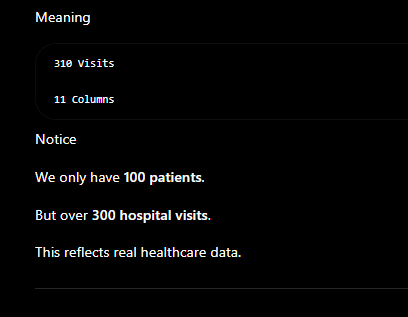

In [17]:
ehr_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   visit_id            312 non-null    object
 1   patient_id          312 non-null    object
 2   visit_date          312 non-null    object
 3   hospital            312 non-null    object
 4   doctor              312 non-null    object
 5   admission_type      312 non-null    object
 6   diagnosis           312 non-null    object
 7   blood_pressure_sys  312 non-null    int64 
 8   blood_pressure_dia  312 non-null    int64 
 9   heart_rate          312 non-null    int64 
 10  discharge_status    312 non-null    object
dtypes: int64(3), object(8)
memory usage: 26.9+ KB


Check

Missing values
Data types
Number of records

In [18]:
ehr_df.describe(include="all")

,visit_id,patient_id,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,discharge_status
count,312,312,312,312,312,312,312,312.000000,312.000000,312.000000,312
unique,312,100,257,3,5,3,8,NaN,NaN,NaN,3
top,V0312,P003,2025-10-26,Regional Medical Center,Dr. Lee,Inpatient,Chest Pain,NaN,NaN,NaN,Admitted
freq,1,5,3,107,80,118,46,NaN,NaN,NaN,120
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,136.134615,79.913462,90.326923,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.467082,11.766575,17.236081,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.000000,60.000000,60.000000,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,117.000000,70.000000,77.000000,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,136.000000,80.000000,89.000000,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,154.000000,90.000000,105.000000,NaN


In [19]:
ehr_df["diagnosis"].value_counts()

,count
diagnosis,
Chest Pain,46
COPD,44
Pneumonia,42
Kidney Disease,42
Type 2 Diabetes,38
Heart Failure,37
Asthma,34
Hypertension,29


Count Admission Types

In [20]:
ehr_df["admission_type"].value_counts()

,count
admission_type,
Inpatient,118
Emergency,103
Outpatient,91


Why this matters for Healthcare Analytics

The EHR is the core clinical data source. It captures what happened during each patient encounter.

Analysts use this table to answer questions like:

How many patients were diagnosed with diabetes?
Which hospital had the most emergency visits?
What is the average heart rate for patients with pneumonia?
How many times did each patient visit the hospital?

Without the EHR, there would be no clinical history to analyze.

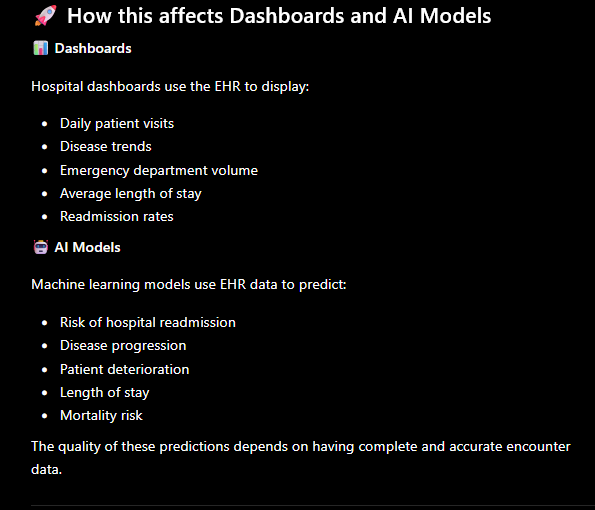

Code Pattern to Remember
Create Lookup Lists
(Diagnoses, Doctors, Hospitals)
        ↓
Loop Through Each Patient
        ↓
Generate Multiple Visits
        ↓
Assign Clinical Information
        ↓
Store Each Visit as a Dictionary
        ↓
Append to List
        ↓
Convert List → DataFrame
        ↓
Explore the Dataset

Section 6: Build the Laboratory Information System (LIS)

Real Hospital Scenario

Imagine a patient comes to the Emergency Department with chest pain.

The doctor examines the patient and orders several lab tests.



Patient Visit

↓

Doctor

↓

Orders Lab Tests

↓

Laboratory

↓

Results Returned

↓

Stored in Laboratory Information System (LIS)

Doctor orders:

CBC
Glucose
Troponin
Creatinine

The laboratory performs the tests.

The results do NOT get stored inside the EHR first.

They are first stored inside the Laboratory Information System (LIS).

This is another healthcare data silo.

What this code does

We will create a synthetic Laboratory Information System.

Each hospital visit can have multiple lab tests.

Each lab record contains

Lab ID
Visit ID
Patient ID
Test Name
Test Result
Unit
Test Date

One visit may have Multiple rows.

Visit V001

↓

CBC

↓

Glucose

↓

Creatinine

↓

Troponin

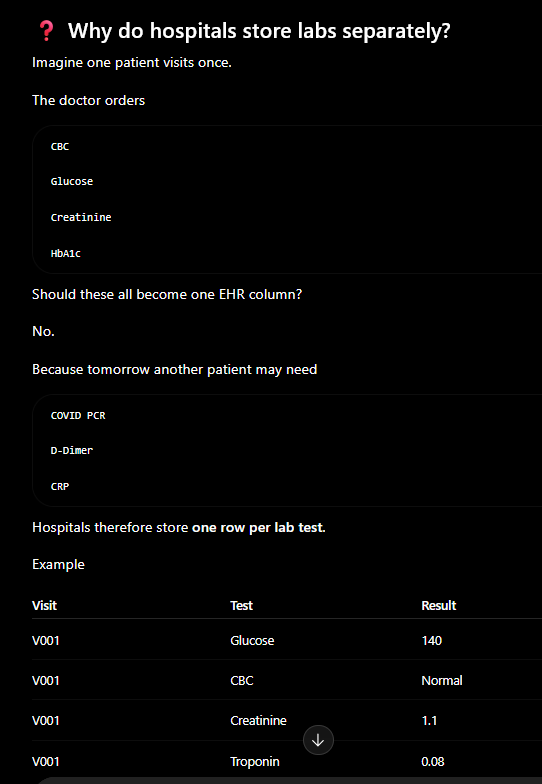

In [21]:
lab_tests = {

    "Glucose": {
        "unit": "mg/dL",
        "min": 70,
        "max": 180
    },

    "HbA1c": {
        "unit": "%",
        "min": 4.5,
        "max": 10.5
    },

    "Creatinine": {
        "unit": "mg/dL",
        "min": 0.5,
        "max": 2.5
    },

    "Troponin": {
        "unit": "ng/mL",
        "min": 0.00,
        "max": 2.00
    },

    "WBC": {
        "unit": "10^9/L",
        "min": 3,
        "max": 15
    }

}

lab_records = []

lab_counter = 1

for _, visit in ehr_df.iterrows():

    number_of_tests = random.randint(2,5)

    selected_tests = random.sample(
        list(lab_tests.keys()),
        number_of_tests
    )

    for test in selected_tests:

        info = lab_tests[test]

        value = round(
            random.uniform(info["min"], info["max"]),
            2
        )

        lab_records.append({

            "lab_id": f"L{lab_counter:05d}",

            "visit_id": visit["visit_id"],

            "patient_id": visit["patient_id"],

            "test_date": visit["visit_date"],

            "test_name": test,

            "result": value,

            "unit": info["unit"]

        })

        lab_counter += 1

lab_df = pd.DataFrame(lab_records)

In [22]:
lab_df.head()

,lab_id,visit_id,patient_id,test_date,test_name,result,unit
0,L00001,V0001,P001,2026-03-15,HbA1c,10.01,%
1,L00002,V0001,P001,2026-03-15,Troponin,1.98,ng/mL
2,L00003,V0002,P002,2025-05-08,HbA1c,8.77,%
3,L00004,V0002,P002,2025-05-08,WBC,12.94,10^9/L
4,L00005,V0002,P002,2025-05-08,Glucose,153.76,mg/dL


Notice

The same visit appears multiple times.

That is expected.

One visit → Many lab tests.

Explore the Dataset
Number of Lab Results

In [23]:
lab_df.shape

(1102, 7)

1200 Lab Results

7 Columns

In [24]:
lab_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1102 entries, 0 to 1101
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lab_id      1102 non-null   object 
 1   visit_id    1102 non-null   object 
 2   patient_id  1102 non-null   object 
 3   test_date   1102 non-null   object 
 4   test_name   1102 non-null   object 
 5   result      1102 non-null   float64
 6   unit        1102 non-null   object 
dtypes: float64(1), object(6)
memory usage: 60.4+ KB


Missing values
Numeric columns
Date columns

In [25]:
lab_df["test_name"].value_counts()

,count
test_name,
Creatinine,230
HbA1c,221
WBC,219
Troponin,217
Glucose,215


Healthcare analysts use this to understand test utilization.

Average Result by Test
lab_df.groupby("test_name")["result

In [26]:
lab_df.groupby("test_name")["result"].mean()

,result
test_name,
Creatinine,1.539522
Glucose,125.453256
HbA1c,7.555882
Troponin,1.016129
WBC,8.644155


A common analysis for monitoring lab trends.

Why this matters for Healthcare Analytics

Laboratory data is often one of the strongest predictors in healthcare.

Examples:

Elevated Troponin → Possible heart attack.
High HbA1c → Poor diabetes control.
High Creatinine → Kidney dysfunction.
High WBC → Possible infection.

Analysts combine lab results with diagnoses to build richer insights.

Code Pattern to Remember

Create Lab Test Dictionary
        ↓
Loop Through Every Visit
        ↓
Choose Random Lab Tests
        ↓
Generate Realistic Results
        ↓
Create One Row Per Test
        ↓
Append to List
        ↓
Convert List → DataFrame
        ↓
Explore the Dataset


Part 1 — Section 7: Build the Pharmacy Information System

Real Hospital Scenario

Imagine a patient visits the Emergency Department because of high blood pressure.

The doctor diagnoses Hypertension.

The doctor then prescribes medication.




Diagnosis:
Hypertension

↓

Prescription

↓

Lisinopril 10 mg

↓

Sent to Pharmacy

Notice something important.

The doctor records the diagnosis inside the EHR.

The medication is stored inside the Pharmacy System.

These are two different databases.

Real Healthcare Data Flow

Patient

↓

Doctor Visit

↓

EHR
(Diagnosis)

↓

Prescription Order

↓

Pharmacy Information System

↓

Medication Dispensed

Hospitals separate these systems because

EHR manages clinical documentation
Pharmacy manages medications
Pharmacy tracks inventory
Pharmacy tracks dispensing history

What this code does

This code creates a synthetic Pharmacy Information System.

Each visit can receive

One or more medications

Each medication record contains

Prescription ID
Visit ID
Patient ID
Medication Name
Dose
Frequency
Duration
Prescription Date

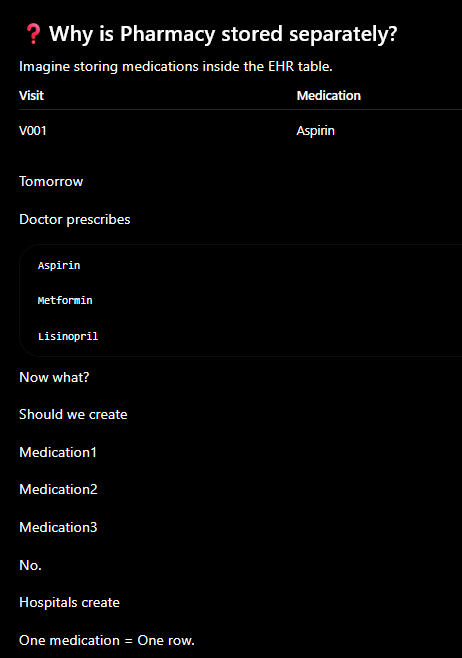

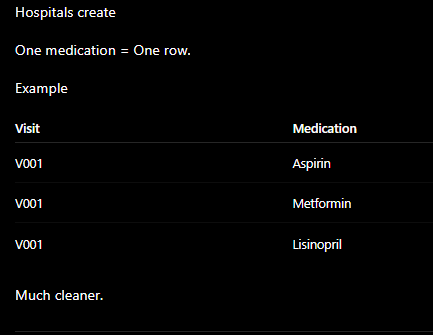

In [27]:
medications = {

    "Hypertension": [
        "Lisinopril",
        "Amlodipine",
        "Losartan"
    ],

    "Type 2 Diabetes": [
        "Metformin",
        "Insulin",
        "Glipizide"
    ],

    "Asthma": [
        "Albuterol",
        "Budesonide"
    ],

    "Heart Failure": [
        "Furosemide",
        "Spironolactone"
    ],

    "Pneumonia": [
        "Azithromycin",
        "Amoxicillin"
    ],

    "Chest Pain": [
        "Aspirin",
        "Nitroglycerin"
    ],

    "COPD": [
        "Tiotropium",
        "Salbutamol"
    ],

    "Kidney Disease": [
        "Sodium Bicarbonate"
    ]
}

doses = [
    "5 mg",
    "10 mg",
    "20 mg",
    "40 mg",
    "500 mg"
]

frequencies = [
    "Once Daily",
    "Twice Daily",
    "Every 8 Hours"
]

pharmacy_records = []

prescription_counter = 1

for _, visit in ehr_df.iterrows():

    diagnosis = visit["diagnosis"]

    meds = medications.get(diagnosis, [])

    number_of_meds = random.randint(1, len(meds))

    selected = random.sample(
        meds,
        number_of_meds
    )

    for med in selected:

        pharmacy_records.append({

            "prescription_id": f"RX{prescription_counter:05d}",

            "visit_id": visit["visit_id"],

            "patient_id": visit["patient_id"],

            "prescription_date": visit["visit_date"],

            "medication": med,

            "dose": random.choice(doses),

            "frequency": random.choice(frequencies),

            "duration_days": random.choice([5,7,10,14,30])

        })

        prescription_counter += 1

pharmacy_df = pd.DataFrame(pharmacy_records)

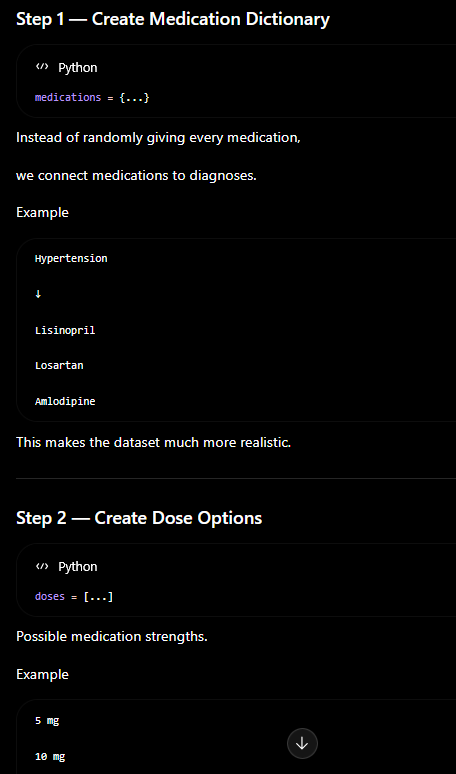

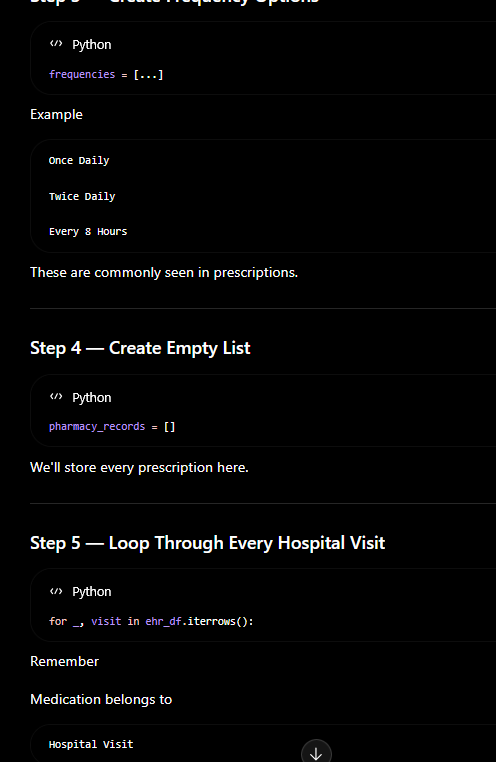

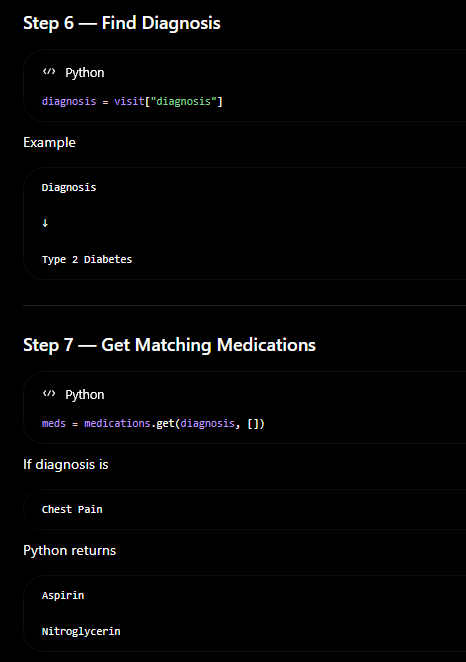

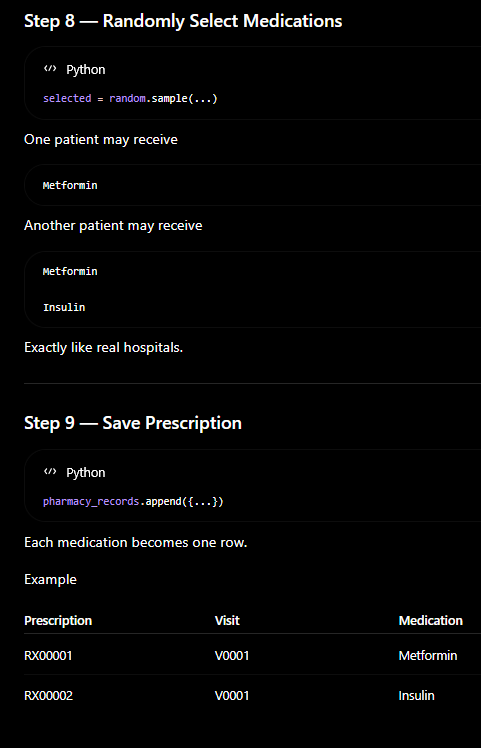

View and inspect dataset


In [28]:
pharmacy_df.head()

,prescription_id,visit_id,patient_id,prescription_date,medication,dose,frequency,duration_days
0,RX00001,V0001,P001,2026-03-15,Lisinopril,20 mg,Twice Daily,7
1,RX00002,V0001,P001,2026-03-15,Amlodipine,5 mg,Once Daily,5
2,RX00003,V0001,P001,2026-03-15,Losartan,40 mg,Every 8 Hours,10
3,RX00004,V0002,P002,2025-05-08,Spironolactone,500 mg,Every 8 Hours,7
4,RX00005,V0003,P002,2025-01-06,Losartan,5 mg,Once Daily,10


In [29]:
pharmacy_df.shape

(480, 8)

Meaning

540 Prescriptions

8 Column

In [30]:
pharmacy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   prescription_id    480 non-null    object
 1   visit_id           480 non-null    object
 2   patient_id         480 non-null    object
 3   prescription_date  480 non-null    object
 4   medication         480 non-null    object
 5   dose               480 non-null    object
 6   frequency          480 non-null    object
 7   duration_days      480 non-null    int64 
dtypes: int64(1), object(7)
memory usage: 30.1+ KB


In [31]:
pharmacy_df["medication"].value_counts()

,count
medication,
Sodium Bicarbonate,42
Salbutamol,37
Amoxicillin,35
Aspirin,33
Azithromycin,32
Nitroglycerin,31
Furosemide,29
Spironolactone,29
Tiotropium,29


In [32]:
pharmacy_df["frequency"].value_counts()

,count
frequency,
Once Daily,169
Every 8 Hours,156
Twice Daily,155


Why this matters for Healthcare Analytics

Pharmacy data helps answer questions like:

Which medications are prescribed most often?
Are diabetic patients receiving appropriate medication?
Which medications are associated with readmission?
How many patients receive antibiotics?
Are prescriptions following clinical guidelines?

Without pharmacy data, you only know what disease a patient has,

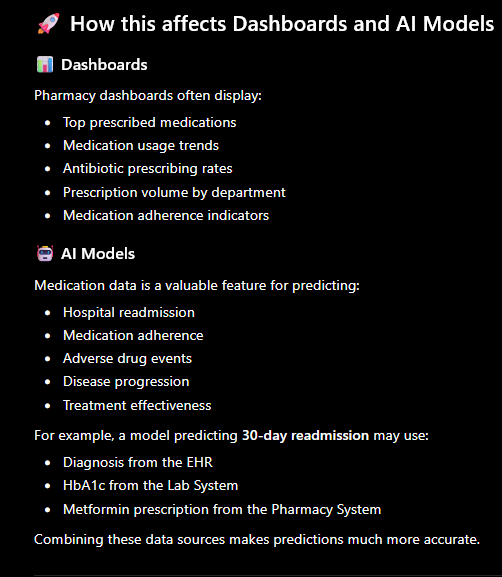

Code Pattern to Remember

Create Diagnosis → Medication Mapping
              ↓
Loop Through Every Visit
              ↓
Find Visit Diagnosis
              ↓
Select Appropriate Medication(s)
              ↓
Create One Row Per Prescription
              ↓
Append to List
              ↓
Convert List → DataFrame
              ↓
Explore the Dataset

Part 1 — Section 8: Build the Billing & Claims System


REal Hospital Scenario

Imagine a patient visits the Emergency Department.

The doctor examines the patient.

The laboratory performs tests.

The pharmacy dispenses medications.

Now someone has to pay for all those services.

The Billing Department creates an insurance claim.

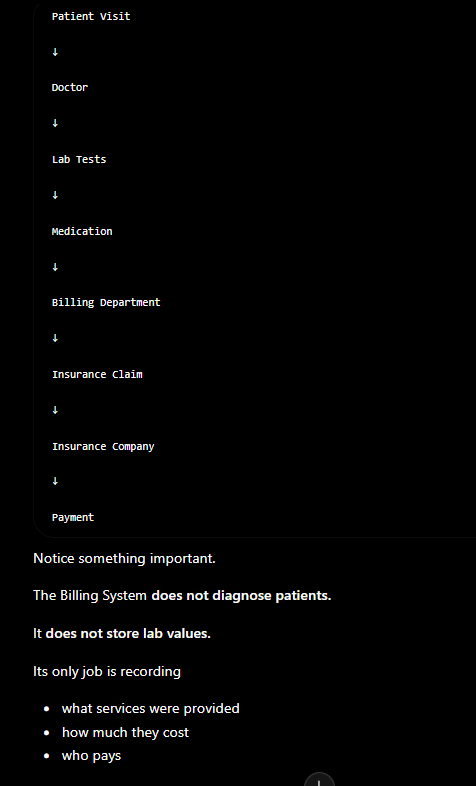

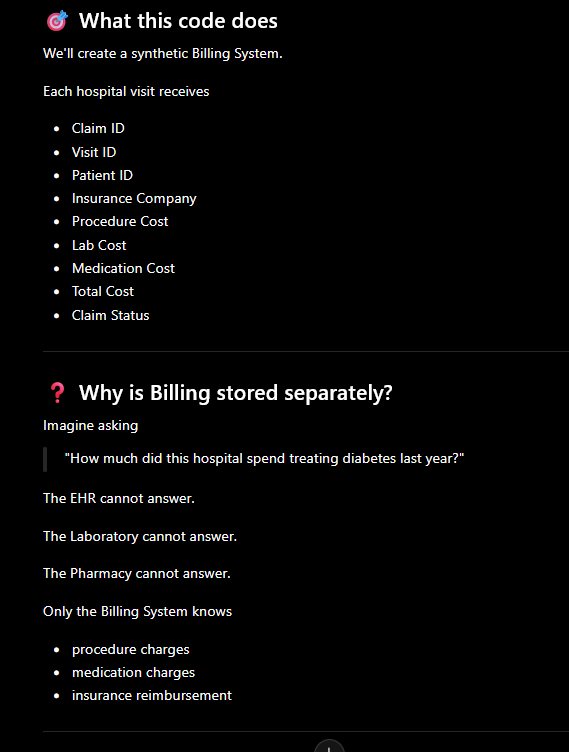

In [33]:
insurance_companies = [
    "Blue Cross",
    "Aetna",
    "United Health",
    "Cigna",
    "Medicare",
    "Self Pay"
]

claim_status = [
    "Paid",
    "Pending",
    "Denied"
]

billing_records = []

claim_counter = 1

for _, visit in ehr_df.iterrows():

    procedure_cost = random.randint(300,2500)

    lab_cost = random.randint(50,600)

    medication_cost = random.randint(20,400)

    total_cost = (
        procedure_cost +
        lab_cost +
        medication_cost
    )

    billing_records.append({

        "claim_id": f"C{claim_counter:05d}",

        "visit_id": visit["visit_id"],

        "patient_id": visit["patient_id"],

        "insurance": random.choice(insurance_companies),

        "procedure_cost": procedure_cost,

        "lab_cost": lab_cost,

        "medication_cost": medication_cost,

        "total_cost": total_cost,

        "claim_status": random.choice(claim_status)

    })

    claim_counter += 1

billing_df = pd.DataFrame(billing_records)

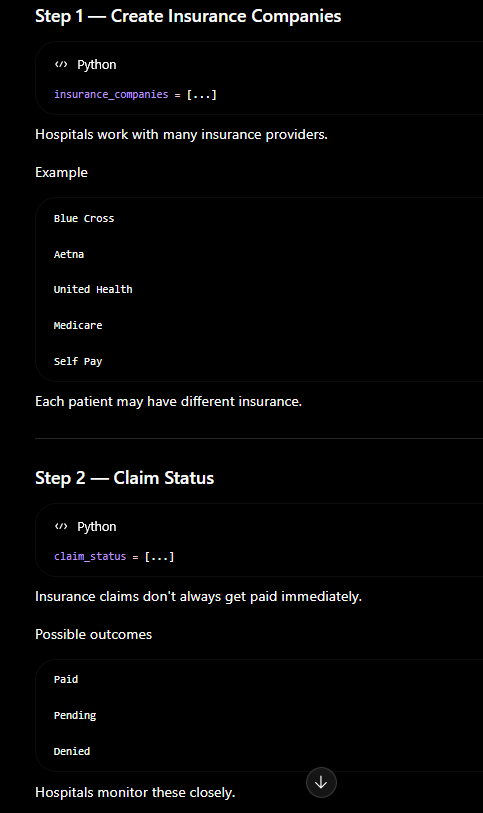

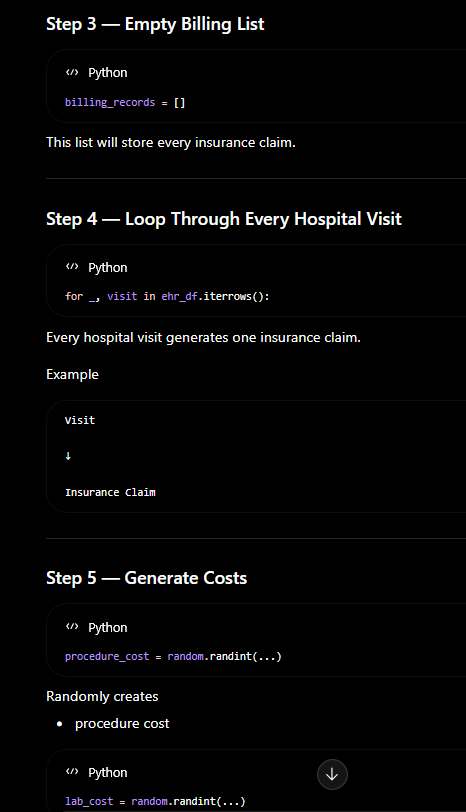

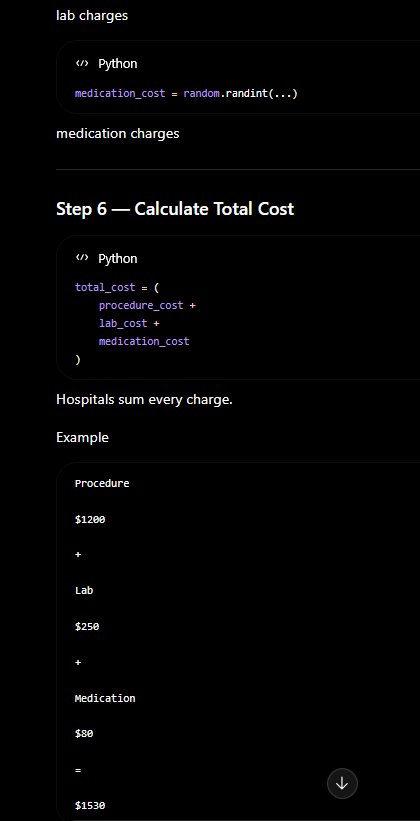

View the Dataset

In [34]:
billing_df.head()

,claim_id,visit_id,patient_id,insurance,procedure_cost,lab_cost,medication_cost,total_cost,claim_status
0,C00001,V0001,P001,Aetna,1698,241,128,2067,Paid
1,C00002,V0002,P002,Medicare,1362,158,242,1762,Paid
2,C00003,V0003,P002,Blue Cross,323,454,79,856,Paid
3,C00004,V0004,P002,Cigna,2254,521,374,3149,Denied
4,C00005,V0005,P002,Medicare,2293,360,336,2989,Pending


In [35]:
billing_df.shape

(312, 9)

meaning-312 Claims

9 Columns

In [36]:
billing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   claim_id         312 non-null    object
 1   visit_id         312 non-null    object
 2   patient_id       312 non-null    object
 3   insurance        312 non-null    object
 4   procedure_cost   312 non-null    int64 
 5   lab_cost         312 non-null    int64 
 6   medication_cost  312 non-null    int64 
 7   total_cost       312 non-null    int64 
 8   claim_status     312 non-null    object
dtypes: int64(4), object(5)
memory usage: 22.1+ KB


In [37]:
billing_df["insurance"].value_counts()

,count
insurance,
Cigna,60
Medicare,57
Blue Cross,55
Aetna,51
Self Pay,50
United Health,39


Hospitals frequently analyze payer mix.

In [38]:
billing_df["claim_status"].value_counts()

,count
claim_status,
Pending,109
Paid,106
Denied,97


Useful for revenue cycle analytics.

In [39]:
billing_df["total_cost"].describe()

,total_cost
count,312.000000
mean,1939.945513
std,666.923464
min,612.000000
25%,1355.000000
50%,1880.500000
75%,2505.000000
max,3239.000000


Average claim
Minimum
Maximum
Median

Why this matters for Healthcare Analytics

Billing data answers questions like:

What is the average cost of treating pneumonia?
Which insurance company pays the fastest?
How many claims are denied?
Which diagnosis generates the highest cost?
Which department produces the highest revenue?

Without Billing, hospitals cannot perform financial analytics.

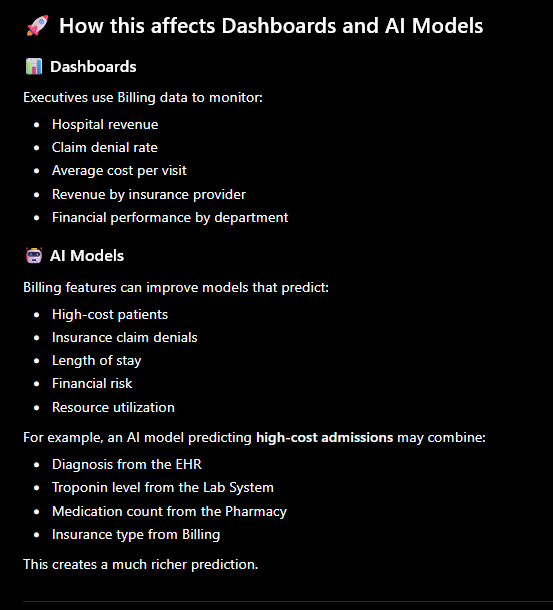

In the next phase, we'll transition from data generation to data engineering, following a realistic healthcare analytics pipeline:

Patient Visits
      ↓
EHR + Lab + Pharmacy + Billing
      ↓
🧹 Data Cleaning
      ↓
🔗 Data Harmonization
      ↓
🕒 Timeline Alignment
      ↓
🏥 Episode Construction
      ↓
📅 Choose Index Date
      ↓
⏪ Build Lookback Window
      ↓
🔮 Build Prediction Window
      ↓
⚠️ Define Risk Period
      ↓
🧠 Feature Engineering
      ↓
📊 Machine Learning / Dashboard

Before We Continue...

At this point, our data is still raw. Each system is isolated, just like in real healthcare organizations.

In the next phase, we'll transition from data generation to data engineering, following a realistic healthcare analytics pipeline:

Patient Visits
      ↓
EHR + Lab + Pharmacy + Billing
      ↓
🧹 Data Cleaning
      ↓
🔗 Data Harmonization
      ↓
🕒 Timeline Alignment
      ↓
🏥 Episode Construction
      ↓
📅 Choose Index Date
      ↓
⏪ Build Lookback Window
      ↓
🔮 Build Prediction Window
      ↓
⚠️ Define Risk Period
      ↓
🧠 Feature Engineering
      ↓
📊 Machine Learning / Dashboard

From here onward, you'll move from creating synthetic healthcare systems to building an analytics-ready dataset, exactly like a healthcare data engineer or clinical data scientist would in a real hospital.

Part 2 — Section 9: Data Cleaning

Real Hospital Scenario

Imagine NorthRiver Hospital has just received yesterday's data.

Electronic Health Record

↓

Laboratory System

↓

Pharmacy System

↓

Billing System

Every department exported their own files.

The hospital now wants to answer questions like:

How many diabetic patients were admitted?
What was the average glucose level?
Which medications were prescribed?
What was the treatment cost?

But before answering any of these questions, the data engineering team must clean the data.

Healthcare rule: Never trust raw data.

Real hospital data almost always contains:

Missing values
Duplicate records
Wrong data types
Impossible values
Different formats

Cleaning is the first step before any analytics or AI.

📌 What this section does

We will clean our healthcare datasets by checking:

Missing values
Duplicate records
Data types
Invalid values
Consistency

This is exactly what healthcare data engineers do before building dashboards or machine learning models.

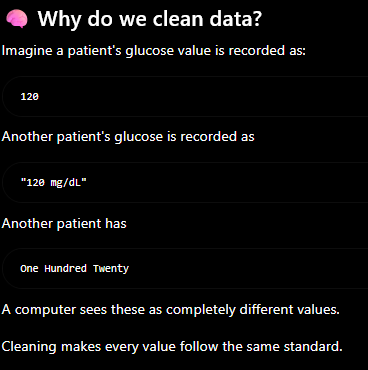

Step 1 — Check Missing Values
📖 What this code does

This code counts how many missing values exist in every column.

Missing values are extremely common in healthcare.

Example

Patient forgot DOB

↓

DOB becomes NULL

or

Doctor never ordered Troponin

↓

Troponin = Missing

Finding missing values early prevents dashboard errors later.

In [40]:
ehr_df.isnull().sum()

,0
visit_id,0
patient_id,0
visit_date,0
hospital,0
doctor,0
admission_type,0
diagnosis,0
blood_pressure_sys,0
blood_pressure_dia,0
heart_rate,0


In [41]:
lab_df.isnull().sum()

,0
lab_id,0
visit_id,0
patient_id,0
test_date,0
test_name,0
result,0
unit,0


In [42]:
pharmacy_df.isnull().sum()

,0
prescription_id,0
visit_id,0
patient_id,0
prescription_date,0
medication,0
dose,0
frequency,0
duration_days,0


In [43]:
billing_df.isnull().sum()

,0
claim_id,0
visit_id,0
patient_id,0
insurance,0
procedure_cost,0
lab_cost,0
medication_cost,0
total_cost,0
claim_status,0


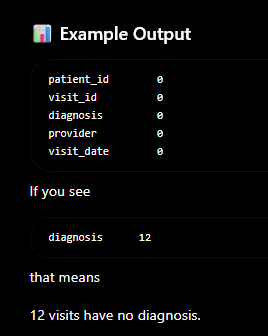

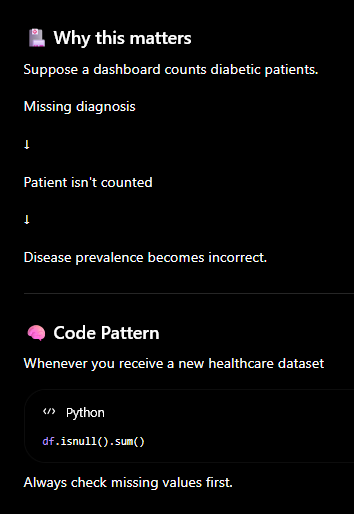

Step 2 — Check Duplicate Records
📖 What this code does

This code checks whether identical rows appear more than once.

Duplicate records happen frequently because

systems resend data
imports run twice
interfaces fail

In [44]:
ehr_df.duplicated().sum()

np.int64(0)

In [45]:
lab_df.duplicated().sum()

np.int64(0)

In [46]:
pharmacy_df.duplicated().sum()

np.int64(0)

In [48]:
billing_df.duplicated().sum()

np.int64(0)

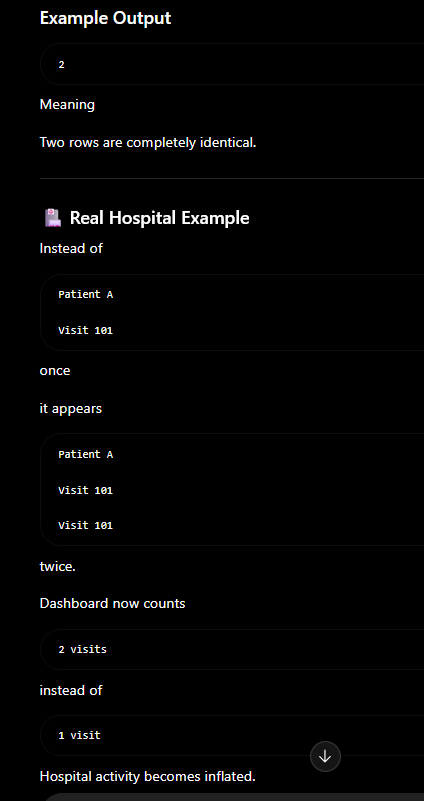

Step 3 — Check Data Types
📖 What this code does

Every column has a data type.

Examples

Age

Integer

Temperature

Float

Diagnosis

Text

Visit Date

Date

Sometimes dates are mistakenly imported as plain text.

In [49]:
ehr_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   visit_id            312 non-null    object
 1   patient_id          312 non-null    object
 2   visit_date          312 non-null    object
 3   hospital            312 non-null    object
 4   doctor              312 non-null    object
 5   admission_type      312 non-null    object
 6   diagnosis           312 non-null    object
 7   blood_pressure_sys  312 non-null    int64 
 8   blood_pressure_dia  312 non-null    int64 
 9   heart_rate          312 non-null    int64 
 10  discharge_status    312 non-null    object
dtypes: int64(3), object(8)
memory usage: 26.9+ KB


In [50]:
lab_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1102 entries, 0 to 1101
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   lab_id      1102 non-null   object 
 1   visit_id    1102 non-null   object 
 2   patient_id  1102 non-null   object 
 3   test_date   1102 non-null   object 
 4   test_name   1102 non-null   object 
 5   result      1102 non-null   float64
 6   unit        1102 non-null   object 
dtypes: float64(1), object(6)
memory usage: 60.4+ KB


In [51]:
pharmacy_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   prescription_id    480 non-null    object
 1   visit_id           480 non-null    object
 2   patient_id         480 non-null    object
 3   prescription_date  480 non-null    object
 4   medication         480 non-null    object
 5   dose               480 non-null    object
 6   frequency          480 non-null    object
 7   duration_days      480 non-null    int64 
dtypes: int64(1), object(7)
memory usage: 30.1+ KB


In [52]:
billing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   claim_id         312 non-null    object
 1   visit_id         312 non-null    object
 2   patient_id       312 non-null    object
 3   insurance        312 non-null    object
 4   procedure_cost   312 non-null    int64 
 5   lab_cost         312 non-null    int64 
 6   medication_cost  312 non-null    int64 
 7   total_cost       312 non-null    int64 
 8   claim_status     312 non-null    object
dtypes: int64(4), object(5)
memory usage: 22.1+ KB


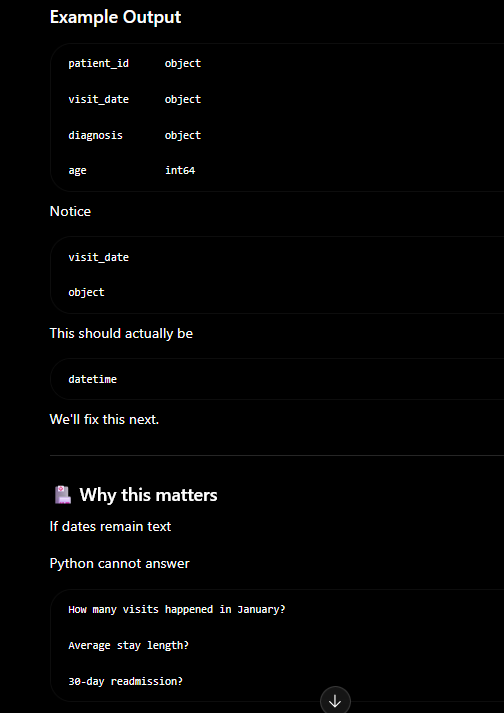

Step 4 — Convert Dates

What this code does

Converts text into real datetime values.

In [53]:
ehr_df["visit_date"] = pd.to_datetime(ehr_df["visit_date"])

In [55]:
lab_df["test_date"] = pd.to_datetime(lab_df["test_date"])

pharmacy_df["prescription_date"] = pd.to_datetime(pharmacy_df["prescription_date"])

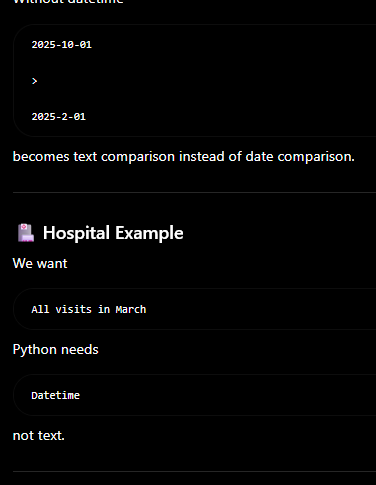

Step 5 — Check Numerical Values
📖 What this code does

Shows summary statistics.

In [56]:
billing_df[[
    "procedure_cost",
    "lab_cost",
    "medication_cost",
    "total_cost"
]].describe()

,procedure_cost,lab_cost,medication_cost,total_cost
count,312.000000,312.00000,312.000000,312.000000
mean,1404.060897,325.00000,210.884615,1939.945513
std,650.367855,156.61124,111.664430,666.923464
min,308.000000,54.00000,20.000000,612.000000
25%,810.750000,192.50000,112.750000,1355.000000
50%,1357.500000,319.50000,212.000000,1880.500000
75%,2028.000000,468.25000,307.750000,2505.000000
max,2497.000000,590.00000,397.000000,3239.000000


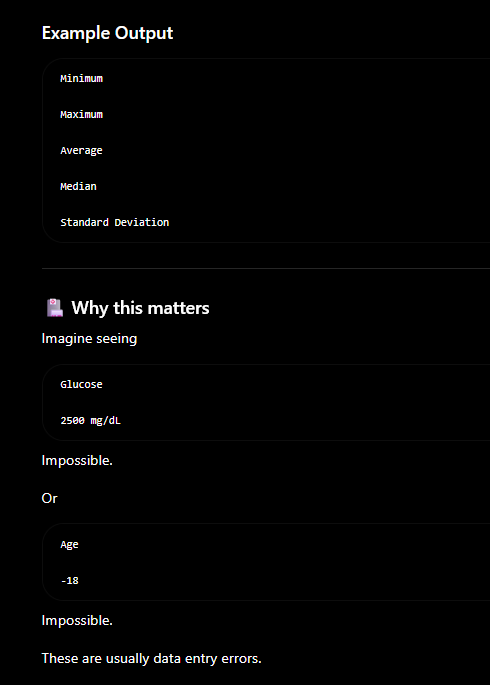

Step 6 — Validate IDs
📖 What this code does

Checks if every patient has a unique identifier.

In [57]:
patient_df["patient_id"].nunique()

100

In [58]:
len(patient_df)

100

Why this matters

If two patients accidentally share

P1045

their medical histories could merge into one record.

This would affect:

Patient timelines
Readmission calculations
Disease prevalence
AI predictions

Part 2 — Section 10: Data Harmonization (Combining Healthcare Data from Multiple Systems)

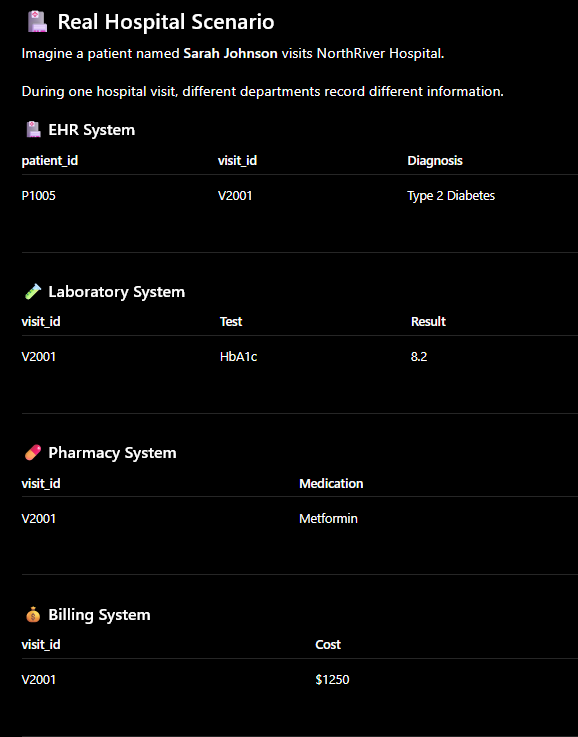

Every department has only part of the patient's story.

None of them alone can answer:

"What happened during Sarah's hospital visit?"

We need to combine everything.

This process is called Data Harmonization.

What this section does

We will merge the silo datasets into one unified patient table.

After harmonization, one row will contain information from:

Patient Registry
EHR
Laboratory
Pharmacy
Billing

This is exactly how healthcare organizations prepare data for dashboards and AI.

Step 1 — Merge Patient Registry with EHR
📖 What this code does

Every visit contains only the patient ID.

To know who the patient is, we merge the Patient Registry.

Think of it like attaching the patient's demographic information to every visi

In [59]:
ehr_patient_df = pd.merge(
    ehr_df,
    patient_df,
    on="patient_id",
    how="left"
)

Understanding the Code
pd.merge()

Combines two DataFrames.

ehr_df

Left table

Contains

diagnosis
visit date
provider
patient_df

Right table

Contains

age
gender
DOB
on="patient_id"

Python matches

P001

↓

P001

instead of guessing.

how="left"

Means

Keep every hospital visit.

Even if patient information is missing.

In [60]:
ehr_patient_df.head()

,visit_id,patient_id,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,discharge_status,first_name,last_name,gender,birth_date,age,city
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,Transferred,Sarah,Smith,Female,1959-03-24,67,Boston
1,V0002,P002,2025-05-08,Regional Medical Center,Dr. Brown,Emergency,Heart Failure,113,79,114,Admitted,Sarah,Johnson,Female,1946-02-07,80,Chicago
2,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,Admitted,Sarah,Johnson,Female,1946-02-07,80,Chicago
3,V0004,P002,2025-04-02,General Hospital,Dr. Smith,Inpatient,Chest Pain,101,86,112,Transferred,Sarah,Johnson,Female,1946-02-07,80,Chicago
4,V0005,P002,2025-01-11,City Hospital,Dr. Wilson,Outpatient,Kidney Disease,119,87,71,Admitted,Sarah,Johnson,Female,1946-02-07,80,Chicago


Step 2 — Merge Laboratory Data
📖 What this code does

Now we attach lab results to every visit.

The common key is

visit_id

because labs belong to a visit.

In [61]:
ehr_lab_df = pd.merge(
    ehr_patient_df,
    lab_df,
    on="visit_id",
    how="left"
)

Why visit_id instead of patient_id?

Because one patient may have many visits.

Example

Patient P001

Visit A

↓

HbA1c

Visit B

↓

CBC

Visit C

↓

Troponin

Using only patient_id could mix lab results from different visits.

visit_id keeps each encounter separate.

In [62]:
ehr_lab_df.head()

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,gender,birth_date,age,city,lab_id,patient_id_y,test_date,test_name,result,unit
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,Female,1959-03-24,67,Boston,L00001,P001,2026-03-15,HbA1c,10.01,%
1,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,Female,1959-03-24,67,Boston,L00002,P001,2026-03-15,Troponin,1.98,ng/mL
2,V0002,P002,2025-05-08,Regional Medical Center,Dr. Brown,Emergency,Heart Failure,113,79,114,...,Female,1946-02-07,80,Chicago,L00003,P002,2025-05-08,HbA1c,8.77,%
3,V0002,P002,2025-05-08,Regional Medical Center,Dr. Brown,Emergency,Heart Failure,113,79,114,...,Female,1946-02-07,80,Chicago,L00004,P002,2025-05-08,WBC,12.94,10^9/L
4,V0002,P002,2025-05-08,Regional Medical Center,Dr. Brown,Emergency,Heart Failure,113,79,114,...,Female,1946-02-07,80,Chicago,L00005,P002,2025-05-08,Glucose,153.76,mg/dL


🏥 Why this matters

Now dashboards can answer:

Average HbA1c by diagnosis
High glucose patients
Diabetes monitoring

Without harmonization, diagnosis and lab results live in different systems.

Step 3 — Merge Pharmacy Data
📖 What this code does

Now attach prescribed medications to each visit.

In [63]:
ehr_lab_pharmacy_df = pd.merge(
    ehr_lab_df,
    pharmacy_df,
    on="visit_id",
    how="left"
)

In [64]:
ehr_lab_pharmacy_df.head()

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,test_name,result,unit,prescription_id,patient_id,prescription_date,medication,dose,frequency,duration_days
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,HbA1c,10.01,%,RX00001,P001,2026-03-15,Lisinopril,20 mg,Twice Daily,7
1,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,HbA1c,10.01,%,RX00002,P001,2026-03-15,Amlodipine,5 mg,Once Daily,5
2,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,HbA1c,10.01,%,RX00003,P001,2026-03-15,Losartan,40 mg,Every 8 Hours,10
3,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,Troponin,1.98,ng/mL,RX00001,P001,2026-03-15,Lisinopril,20 mg,Twice Daily,7
4,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,Troponin,1.98,ng/mL,RX00002,P001,2026-03-15,Amlodipine,5 mg,Once Daily,5


Why this matters

Now hospitals can analyze:

Which medications are used for diabetes?
Do patients with higher HbA1c receive insulin?
Medication effectiveness

Step 4 — Merge Billing Data
📖 What this code does

Finally, attach financial information.

In [65]:
healthcare_df = pd.merge(
    ehr_lab_pharmacy_df,
    billing_df,
    on=["visit_id", "patient_id"],
    how="left"
)

Why use both visit_id and patient_id?

This adds an extra validation step.

Both IDs must match.

This reduces the risk of attaching another patient's billing information.

In [66]:
healthcare_df.head()

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,dose,frequency,duration_days,claim_id,insurance,procedure_cost,lab_cost,medication_cost,total_cost,claim_status
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,20 mg,Twice Daily,7,C00001,Aetna,1698,241,128,2067,Paid
1,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,5 mg,Once Daily,5,C00001,Aetna,1698,241,128,2067,Paid
2,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,40 mg,Every 8 Hours,10,C00001,Aetna,1698,241,128,2067,Paid
3,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,20 mg,Twice Daily,7,C00001,Aetna,1698,241,128,2067,Paid
4,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,5 mg,Once Daily,5,C00001,Aetna,1698,241,128,2067,Paid


Step 5 — Verify the Merge
📖 What this code does

Check the size of the new dataset.

In [67]:
healthcare_df.shape

(1685, 37)

Check Columns

In [68]:
healthcare_df.columns

Index(['visit_id', 'patient_id_x', 'visit_date', 'hospital', 'doctor',
       'admission_type', 'diagnosis', 'blood_pressure_sys',
       'blood_pressure_dia', 'heart_rate', 'discharge_status', 'first_name',
       'last_name', 'gender', 'birth_date', 'age', 'city', 'lab_id',
       'patient_id_y', 'test_date', 'test_name', 'result', 'unit',
       'prescription_id', 'patient_id', 'prescription_date', 'medication',
       'dose', 'frequency', 'duration_days', 'claim_id', 'insurance',
       'procedure_cost', 'lab_cost', 'medication_cost', 'total_cost',
       'claim_status'],
      dtype='object')

This confirms that data from all systems is now present.

Check Missing Values After Merge

In [69]:
healthcare_df.isnull().sum()

,0
visit_id,0
patient_id_x,0
visit_date,0
hospital,0
doctor,0
admission_type,0
diagnosis,0
blood_pressure_sys,0
blood_pressure_dia,0
heart_rate,0


This helps identify:

patients without lab tests
visits without medications
missing billing information

These are expected in many real hospital datasets.

How This Affects Dashboards and AI Models
📊 Dashboards

Before harmonization:

EHR dashboard shows diagnoses only.
Lab dashboard shows test results only.
Billing dashboard shows costs only.

No dashboard can answer questions across systems.

After harmonization:

Executives can ask:

Average treatment cost for diabetic patients
HbA1c trends by medication
Cost by diagnosis
Medication use by age group
Disease prevalence by gender

AI Models

Machine learning models need information from multiple sources.

Example features:

| Source           | Feature        |
| ---------------- | -------------- |
| Patient Registry | Age, Gender    |
| EHR              | Diagnosis      |
| Lab              | HbA1c, Glucose |
| Pharmacy         | Medication     |
| Billing          | Total Cost     |


Without harmonization, these features remain isolated, and the model has only part of the patient's story.

Next Section

Now that the data is unified, we'll begin building patient timelines:

Harmonized Dataset
        ↓
🕒 Timeline Alignment
        ↓
🏥 Episode Construction
        ↓
📅 Choose Index Date
        ↓
⏪ Lookback Window
        ↓
🔮 Prediction Window
        ↓
⚠️ Risk Period

Part 2 — Section 11: Timeline Alignment (Building the Patient Timeline)

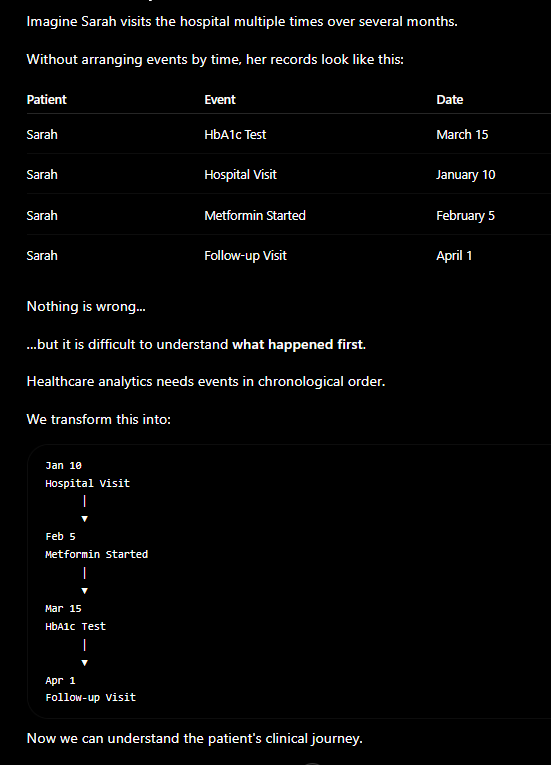

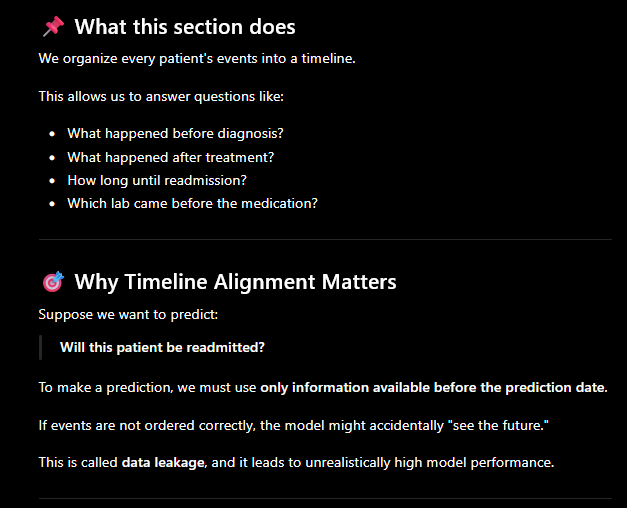

Step 1 — Sort the Data by Patient and Visit Date
📖 What this code does

We sort every patient's hospital visits from oldest to newest.

This creates the foundation of the patient timeline.

In [70]:
healthcare_df = healthcare_df.sort_values(
    by=["patient_id", "visit_date"]
)

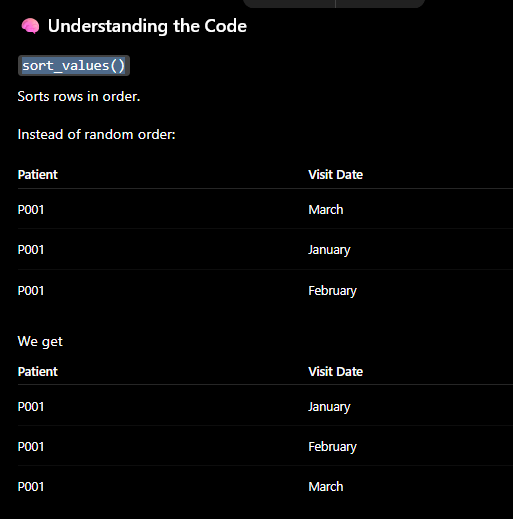

Why this matters

Doctors think in timelines.

Analytics should too.

Without ordering events, we cannot determine:

First diagnosis
Most recent lab
Previous medication
Time between visits

Step 2 — View One Patient's Timeline
📖 What this code does

Instead of looking at thousands of patients, let's inspect one patient's journe

In [73]:
sample_patient = healthcare_df[
    healthcare_df["patient_id"] == "P001"
]

sample_patient

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,dose,frequency,duration_days,claim_id,insurance,procedure_cost,lab_cost,medication_cost,total_cost,claim_status
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,20 mg,Twice Daily,7,C00001,Aetna,1698,241,128,2067,Paid
1,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,5 mg,Once Daily,5,C00001,Aetna,1698,241,128,2067,Paid
2,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,40 mg,Every 8 Hours,10,C00001,Aetna,1698,241,128,2067,Paid
3,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,20 mg,Twice Daily,7,C00001,Aetna,1698,241,128,2067,Paid
4,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,5 mg,Once Daily,5,C00001,Aetna,1698,241,128,2067,Paid
5,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,40 mg,Every 8 Hours,10,C00001,Aetna,1698,241,128,2067,Paid


🏥 Why this matters

Hospitals frequently review timelines to understand:

Disease progression
Medication changes
Repeat admissions
Treatment effectiveness

Step 3 — Calculate Days Between Visits
📖 What this code does

We calculate how many days passed between each hospital visit.

In [79]:
healthcare_df["days_since_last_visit"] = (
    healthcare_df
        .groupby("patient_id")["visit_date"]
        .diff()
        .dt.days
)


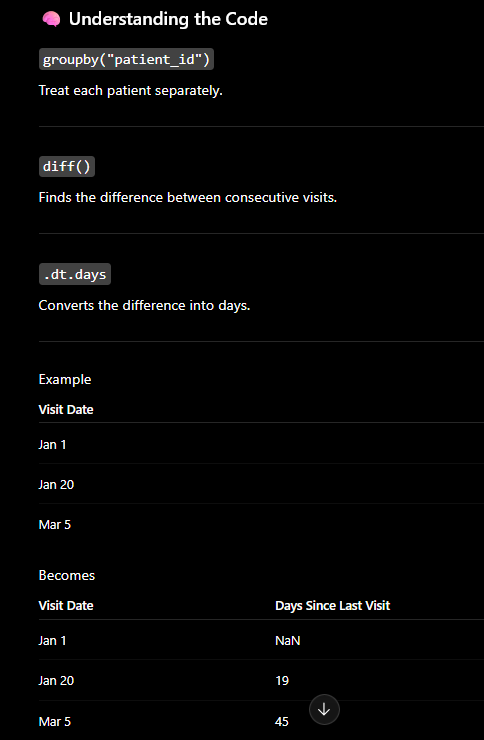

Why this matters

Hospitals monitor:

Frequent Emergency Department visits
Time until readmission
Follow-up compliance
Chronic disease managemen

Step 4 — Identify the First Visit
📖 What this code does

Marks the patient's first hospital visit.

In [75]:
healthcare_df["visit_number"] = (
    healthcare_df
        .groupby("patient_id")
        .cumcount() + 1
)

Why this matters

Many studies compare:

First admission
Second admission
Third admission

This feature is also useful for predicting future hospital utilization.

Step 5 — Visualize One Patient's Timeline
📖 What this code does

Creates a simple timeline for one patient

In [116]:
timeline = healthcare_df[
    healthcare_df["patient_id"]=="P001"
][[
    "visit_date",
    "diagnosis",
    "medication",
    "days_since_last_visit",
    "visit_number"
]]

timeline

,visit_date,diagnosis,medication,days_since_last_visit,visit_number
0,2026-03-15,Hypertension,Lisinopril,NaN,1
1,2026-03-15,Hypertension,Amlodipine,0.0,2
2,2026-03-15,Hypertension,Losartan,0.0,3
3,2026-03-15,Hypertension,Lisinopril,0.0,4
4,2026-03-15,Hypertension,Amlodipine,0.0,5
5,2026-03-15,Hypertension,Losartan,0.0,6


How This Affects Dashboards and AI Models
📊 Dashboards

Timeline alignment enables dashboards to show:

Patient journey over time
Disease progression
Lab trends
Medication changes
Hospital utilization

Without ordering events, trend charts become inaccurate.

🤖 AI Models

Timeline alignment enables features like:

Days since last admission
Number of visits in the past year
Recent HbA1c trend
Medication history
Time between procedures

Without a proper timeline, these features cannot be calculated correctly.

Part 2 — Section 12: Episode Construction (Grouping Related Visits)

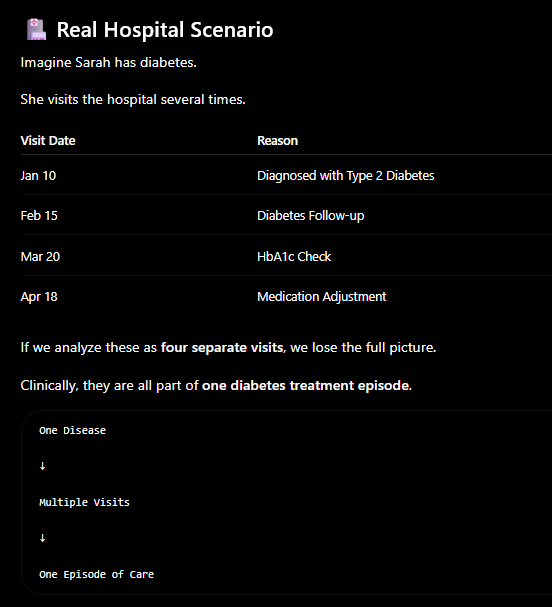

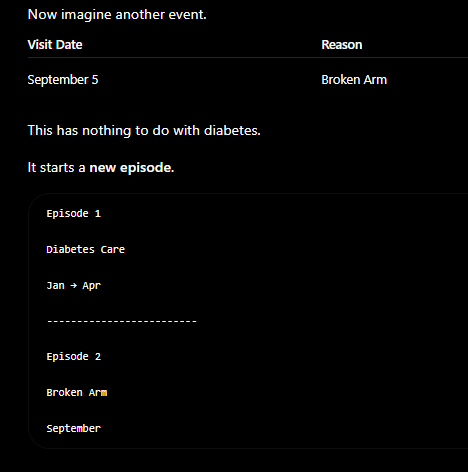

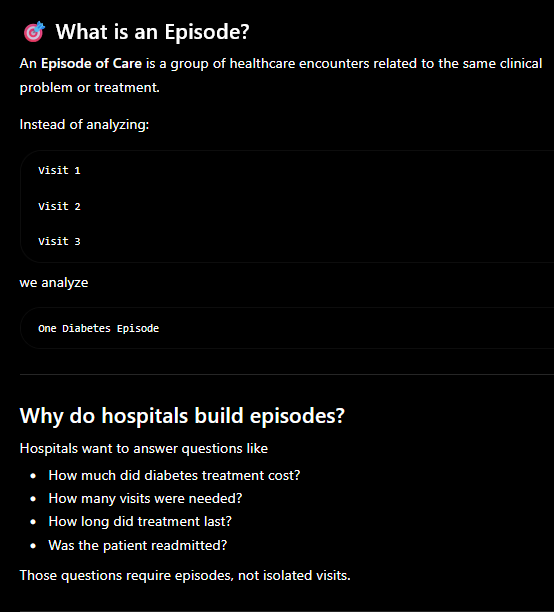

What this section does

We'll create simple episodes by grouping visits that occur within 90 days of each other for the same patient.

Note: Real hospitals often use diagnosis, procedure, and clinical rules too. We're using a simple time-based approach to learn the concept.

Step 1 — Define an Episode Gap
📖 What this code does

We define the maximum gap between visits before starting a new episode.

In [83]:
EPISODE_GAP_DAYS = 90

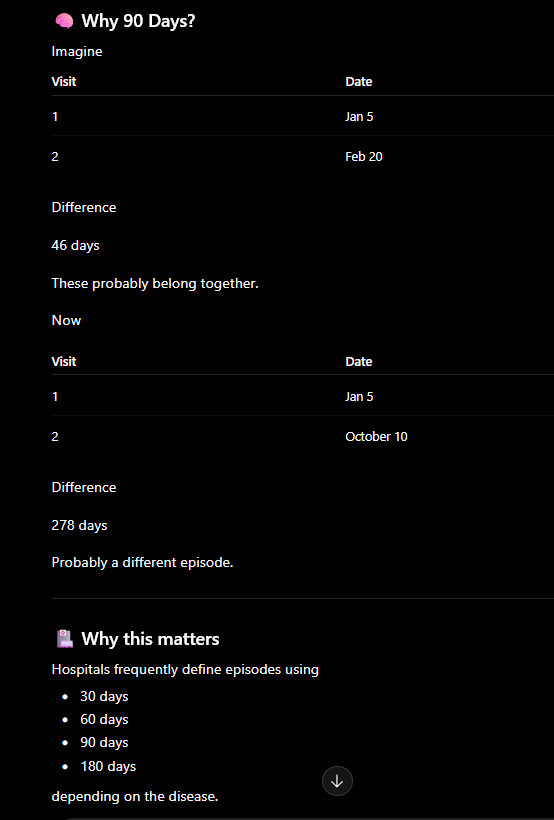

Step 2 — Start a New Episode When the Gap is Large

📖 What this code does

We check whether enough time has passed to begin a new episode.

In [85]:
healthcare_df["new_episode"] = (
    healthcare_df["days_since_last_visit"] > EPISODE_GAP_DAYS
)

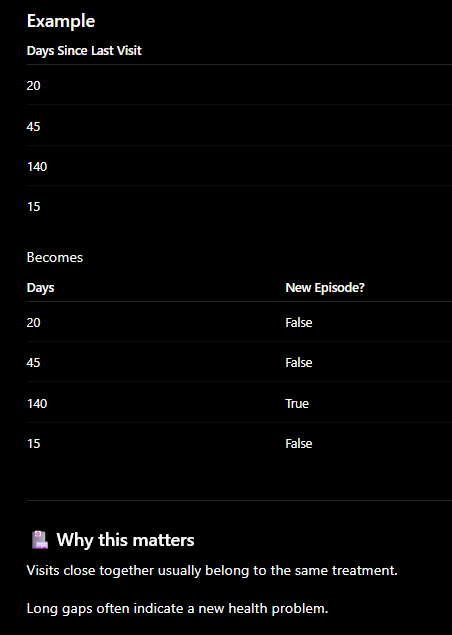

Step 3 — Create Episode Numbers
📖 What this code does

Now we assign an episode number to every visit.

Each time we encounter True, we start a new episode.

In [87]:
healthcare_df["episode_number"] = (
    healthcare_df
        .groupby("patient_id")["new_episode"]
        .cumsum() + 1
)

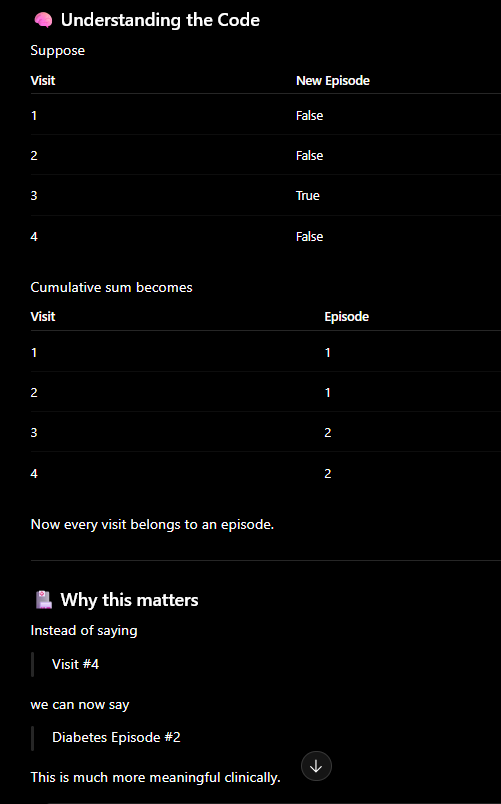

Step 4 — View One Patient's Episodes
📖 What this code does

Let's inspect one patient's timeline and episodes.

In [88]:
healthcare_df[
    healthcare_df["patient_id"] == "P001"
][[
    "visit_date",
    "diagnosis",
    "days_since_last_visit",
    "episode_number"
]]

,visit_date,diagnosis,days_since_last_visit,episode_number
0,2026-03-15,Hypertension,NaN,1
1,2026-03-15,Hypertension,0.0,1
2,2026-03-15,Hypertension,0.0,1
3,2026-03-15,Hypertension,0.0,1
4,2026-03-15,Hypertension,0.0,1
5,2026-03-15,Hypertension,0.0,1


Step 5 — Count Visits Per Episode
📖 What this code does

We summarize each episode by counting how many visits it contains.

In [89]:
episode_summary = (
    healthcare_df
    .groupby(["patient_id", "episode_number"])
    .agg(
        total_visits=("visit_id", "count"),
        first_visit=("visit_date", "min"),
        last_visit=("visit_date", "max")
    )
    .reset_index()
)

episode_summary.head()

,patient_id,episode_number,total_visits,first_visit,last_visit
0,P001,1,6,2026-03-15,2026-03-15
1,P002,1,22,2025-01-06,2025-05-08
2,P003,1,8,2024-08-11,2024-08-11
3,P003,2,18,2025-02-12,2025-05-11
4,P003,3,2,2026-07-02,2026-07-02


Why Episodes Matter

Hospitals often measure:

Total cost per episode
Number of visits per episode
Length of treatment
Readmission within an episode
Outcomes after treatment

Episodes are much more clinically meaningful than isolated visits.

How This Affects Dashboards and AI Models
📊 Dashboards

Without episodes:

Total visits
Total admissions

With episodes:

Average episode length
Average visits per episode
Cost per episode
Chronic disease management
Care pathway analysis

Episodes tell the story of treatment, not just attendance.

🤖 AI Models

Episodes allow us to create features such as:

Number of visits in an episode
Episode duration
Total cost of an episode
Number of medications used
Number of abnormal lab results

These features are often stronger predictors than information from a single visit.

End of Section Summary

We grouped related visits into Episodes of Care.

Individual Visits
        │
        ▼
Measure Time Between Visits
        │
        ▼
Detect Large Gaps
        │
        ▼
Assign Episode Numbers
        │
        ▼
Summarize Each Episode

Instead of treating every visit as a separate event, we now have meaningful clinical episodes that reflect a patient's journey through care.

Part 2 — Section 13: Choosing the Index Date

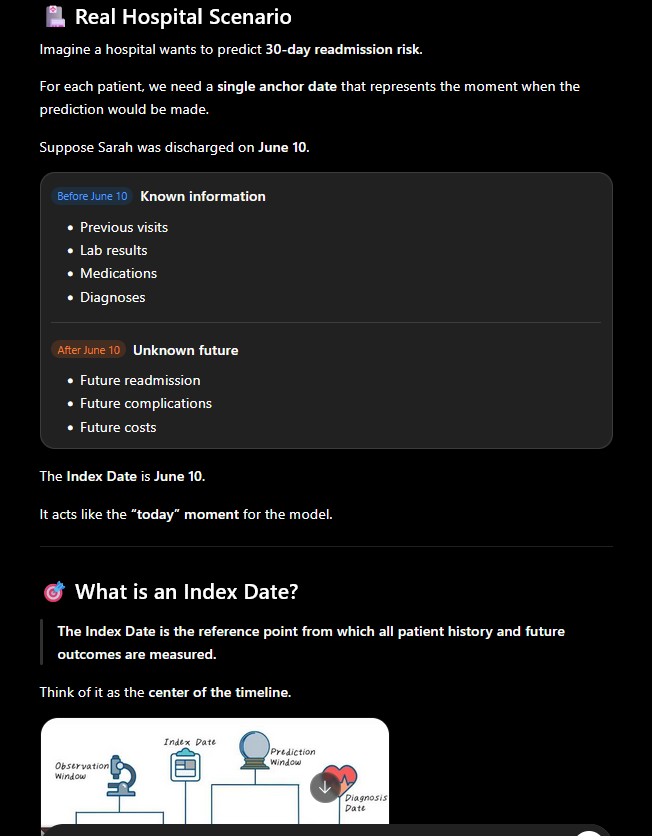

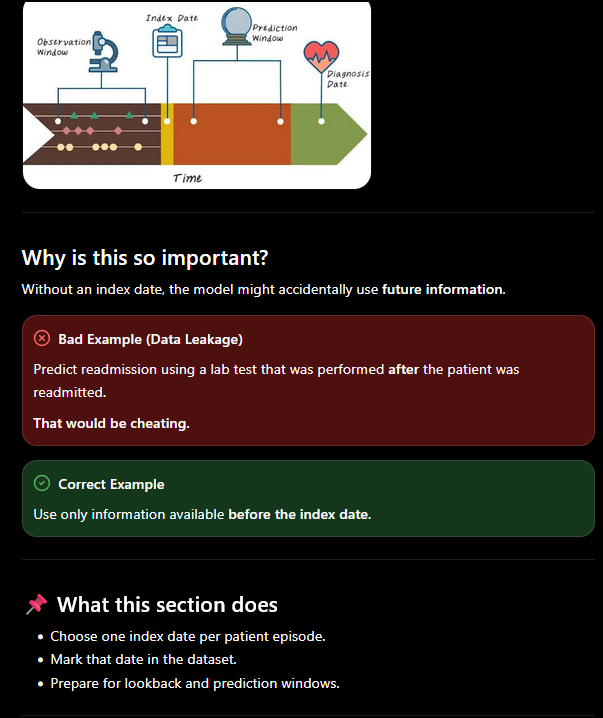

tep 1 — Choose the Index Date
📖 What this code does

We'll use the last visit in each episode as the index date.

This is common in readmission studies because prediction often happens at discharge.

In [90]:
index_df = (

healthcare_df

.groupby(["patient_id", "episode_number"])

.agg(index_date=("visit_date", "max"))

.reset_index()

)

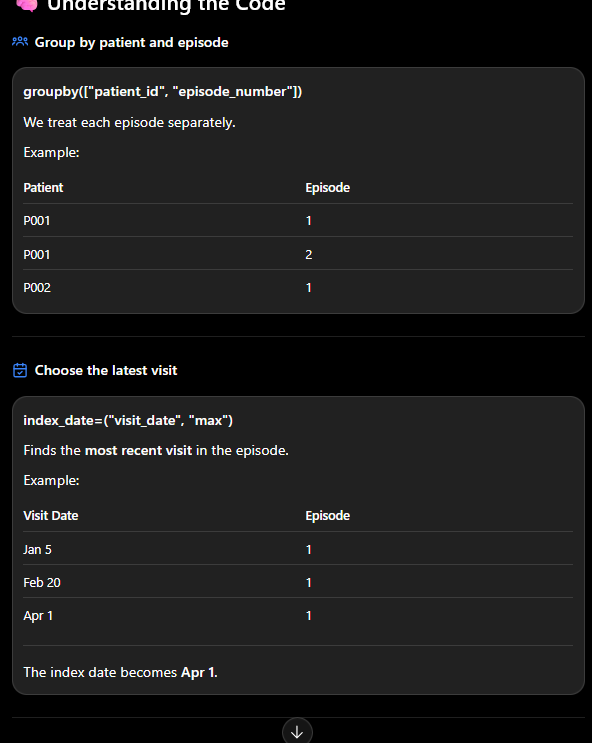

View the Index Table

In [91]:
index_df.head(10)

,patient_id,episode_number,index_date
0,P001,1,2026-03-15
1,P002,1,2025-05-08
2,P003,1,2024-08-11
3,P003,2,2025-05-11
4,P003,3,2026-07-02
5,P004,1,2025-12-02
6,P004,2,2026-04-20
7,P005,1,2025-09-21
8,P006,1,2024-07-06
9,P006,2,2024-11-27


Step 2 — Attach the Index Date Back to the Dataset
📖 What this code does

Adds the index date to every row in that episode.


In [92]:
healthcare_df = pd.merge(

healthcare_df,

index_df,

on=["patient_id", "episode_number"],

how="left"

)

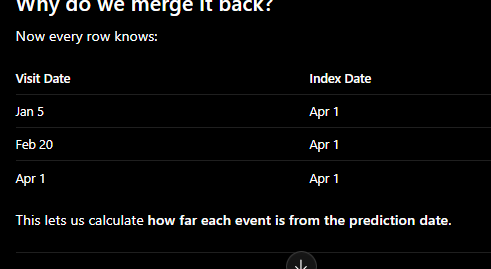

Step 3 — Calculate Days Relative to the Index Date

📖 What this code does

Measures whether an event happened before or after the index date

In [95]:
healthcare_df["days_from_index"] = (

healthcare_df["visit_date"] - healthcare_df["index_date"]

).dt.days

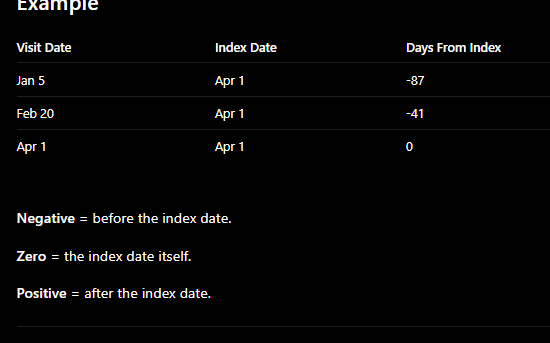

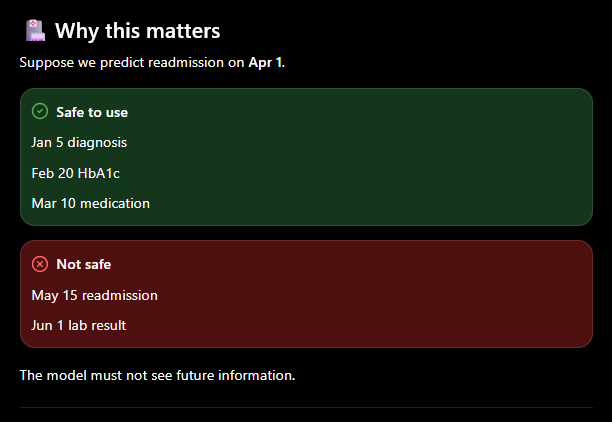

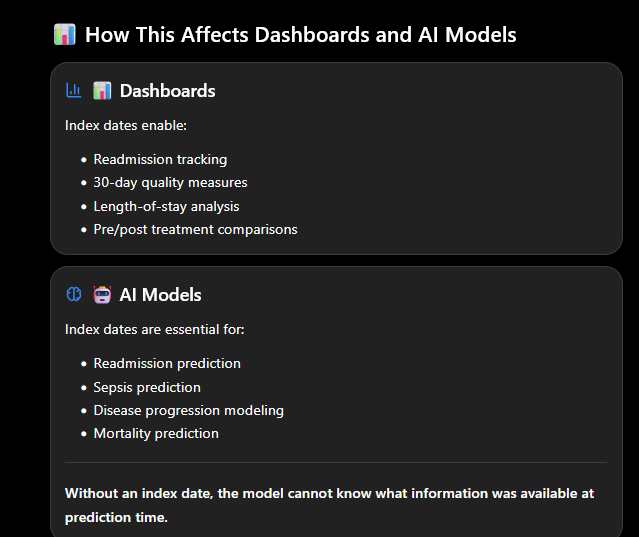

Part 2 — Section 14: Building the Lookback Window

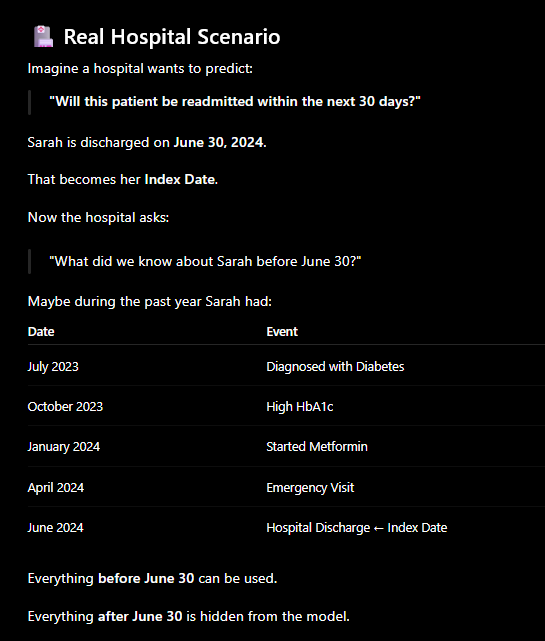

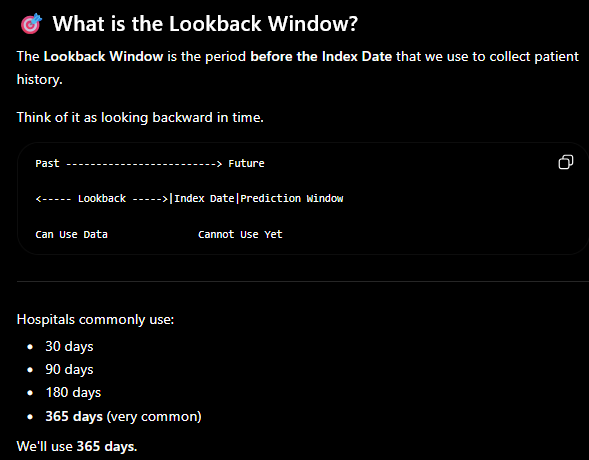

What this section does

We will:

Define a 365-day lookback window.
Keep only events inside that window.
Remove older events.
Prepare patient history for feature engineering.

Step 1 — Define the Lookback Window
📖 What this code does

We tell Python how far back we want to look.

Here, we'll use one year (365 days).

In [96]:
LOOKBACK_DAYS = 365

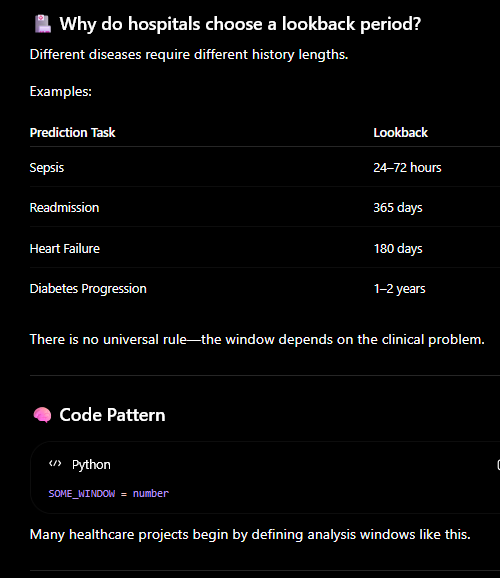

Step 2 — Keep Only Events Inside the Lookback Window

We filter the dataset so that it contains only events that occurred within 365 days before the index date.

In [97]:
lookback_df = healthcare_df[
    (healthcare_df["days_from_index"] >= -LOOKBACK_DAYS) &
    (healthcare_df["days_from_index"] <= 0)
]

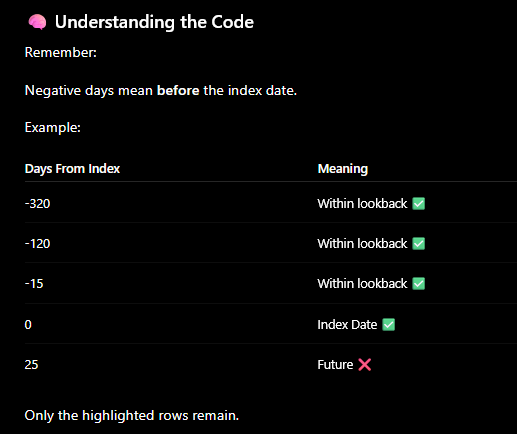

View the Result

In [99]:
lookback_df.head(10)

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,lab_cost,medication_cost,total_cost,claim_status,days_since_last_visit,visit_number,new_episode,episode_number,index_date,days_from_index
0,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,NaN,1,False,1,2026-03-15,0
1,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,0.0,2,False,1,2026-03-15,0
2,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,0.0,3,False,1,2026-03-15,0
3,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,0.0,4,False,1,2026-03-15,0
4,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,0.0,5,False,1,2026-03-15,0
5,V0001,P001,2026-03-15,City Hospital,Dr. Lee,Emergency,Hypertension,139,96,103,...,241,128,2067,Paid,0.0,6,False,1,2026-03-15,0
6,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,...,454,79,856,Paid,NaN,1,False,1,2025-05-08,-122
7,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,...,454,79,856,Paid,0.0,2,False,1,2025-05-08,-122
8,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,...,454,79,856,Paid,0.0,3,False,1,2025-05-08,-122
9,V0003,P002,2025-01-06,Regional Medical Center,Dr. Smith,Inpatient,Hypertension,144,94,87,...,454,79,856,Paid,0.0,4,False,1,2025-05-08,-122


Why this matters

Suppose Sarah returns to the hospital three months later.

Those visits must not be included because they had not happened yet when the prediction was made.

This prevents data leakage.

Step 3 — Compare Before and After Filtering
📖 What this code does

Let's see how much data remains after applying the lookback window.

In [100]:
print("Original Records:", len(healthcare_df))
print("Lookback Records:", len(lookback_df))

Original Records: 1685
Lookback Records: 1685


in here , all the visit in within 1 year , so all data shown


Step 4 — Visualize One Patient's Lookback Window
📖 What this code does

Let's inspect the patient history that remains after filtering.

In [101]:
lookback_df[
    lookback_df["patient_id"] == "P003"
][[
    "visit_date",
    "diagnosis",
    "days_from_index"
]]

,visit_date,diagnosis,days_from_index
28,2024-08-11,COPD,0
29,2024-08-11,COPD,0
30,2024-08-11,COPD,0
31,2024-08-11,COPD,0
32,2024-08-11,COPD,0
33,2024-08-11,COPD,0
34,2024-08-11,COPD,0
35,2024-08-11,COPD,0
36,2025-02-12,Heart Failure,-88
37,2025-02-12,Heart Failure,-88


Step 5 — Verify No Future Data Exists
📖 What this code does

This is a simple quality check.

We confirm that no future events remain.

In [102]:
lookback_df["days_from_index"].max()

0

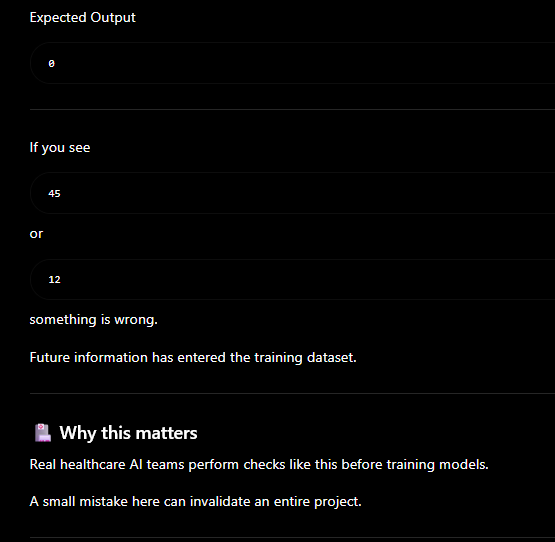

How This Affects Dashboards and AI Models
📊 Dashboards

The lookback window allows dashboards to display:

Previous diagnoses
Previous admissions
Medication history
Lab history
Healthcare utilization

Users can choose:

Last 30 days
Last 6 months
Last year
🤖 AI Models

The lookback window creates the information that becomes model features.

Examples:

Number of hospital visits in the last year
Number of emergency visits
Average HbA1c
Number of medications
Number of abnormal lab tests

Without a lookback window, the model would not know which history belongs to the past.

Part 2 — Section 15: Building the Prediction Window

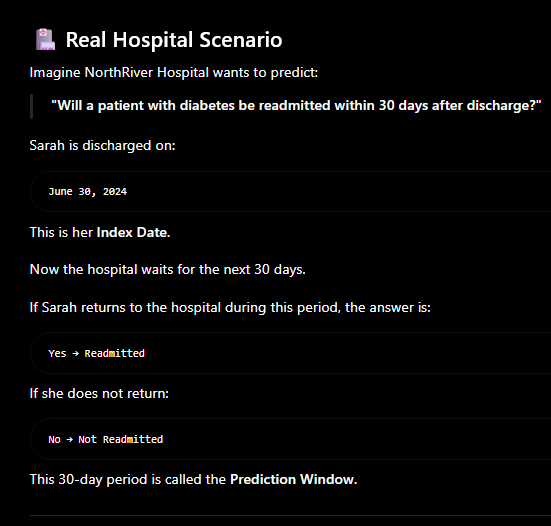

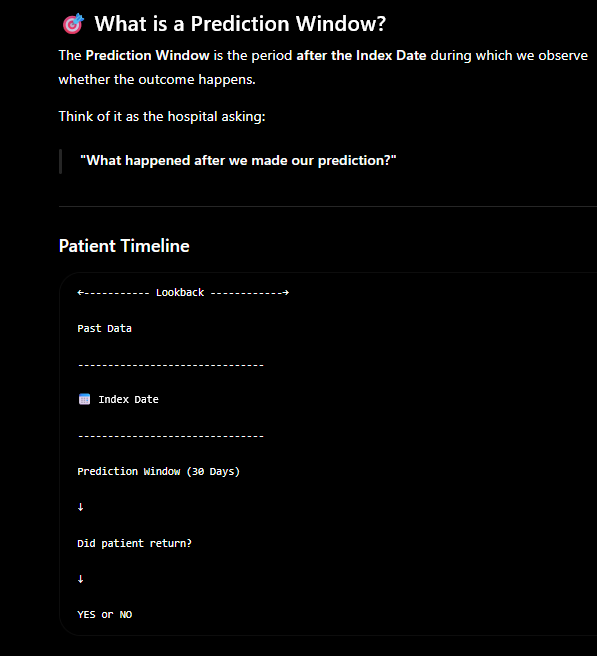

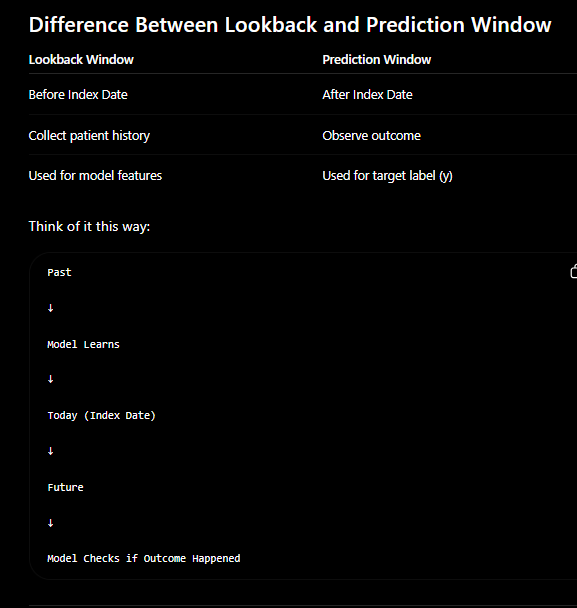

What this section does

We will:

Define a 30-day prediction window.
Find visits occurring within 30 days after the Index Date.
Label each patient as readmitted or not.
Create the target variable (y) for machine learning.

Step 1 — Define the Prediction Window
📖 What this code does

We tell Python that we'll look 30 days into the future.

This is one of the most common prediction windows used in hospitals.

In [107]:
PREDICTION_DAYS = 30

Why 30 Days?

Hospitals often measure:

30-day readmission
30-day mortality
30-day complications

Because these are important quality indicators.

Some projects may use:

7 days
60 days
90 days

depending on the clinical question.

Step 2 — Find Future Visits

What this code does

We search for visits that happened after the Index Date but within 30 days.

These visits determine whether the patient was readmitted.

In [108]:
prediction_df = healthcare_df[
    (healthcare_df["days_from_index"] > 0) &
    (healthcare_df["days_from_index"] <= PREDICTION_DAYS)
]

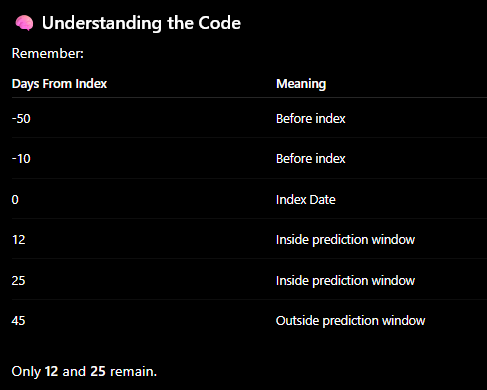

View the Data

In [110]:
prediction_df.head()

,visit_id,patient_id_x,visit_date,hospital,doctor,admission_type,diagnosis,blood_pressure_sys,blood_pressure_dia,heart_rate,...,lab_cost,medication_cost,total_cost,claim_status,days_since_last_visit,visit_number,new_episode,episode_number,index_date,days_from_index


there is no  row  the day from _indexinformation after

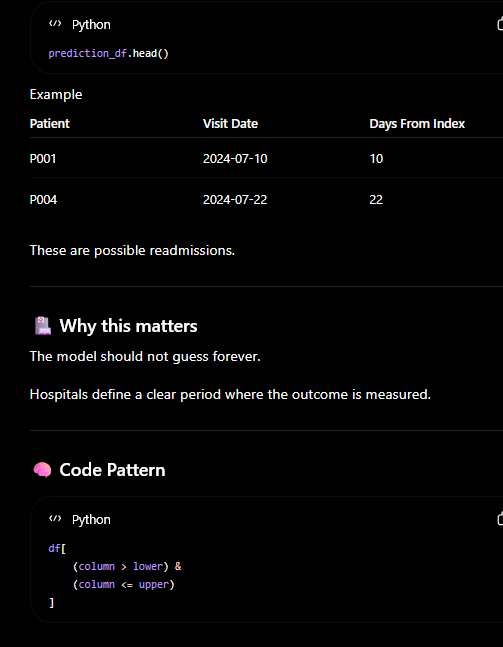

if we find the  readmission after the index_date ,  we will use this as target variable for reeadmission prediction model

Step 3 — Create the Readmission Label

What this code does

Now we create the machine learning target.

If a patient has one or more visits inside the prediction window:

Readmitted = 1

Otherwise:

Readmitted = 0

In [111]:
readmission = (
    prediction_df
    .groupby(["patient_id", "episode_number"])
    .size()
    .reset_index(name="future_visits")
)

readmission["readmitted"] = 1

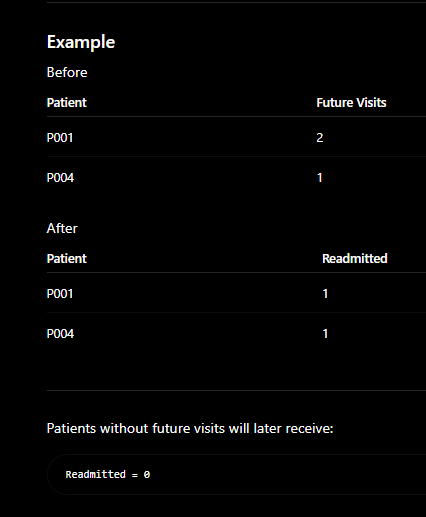

Step 4 — Merge the Label Back
📖 What this code does

We attach the readmission label to every patient episode.

Patients with no future visit receive 0.

In [112]:
episode_summary = pd.merge(
    episode_summary,
    readmission[["patient_id", "episode_number", "readmitted"]],
    on=["patient_id", "episode_number"],
    how="left"
)

episode_summary["readmitted"] = (
    episode_summary["readmitted"]
    .fillna(0)
    .astype(int)
)

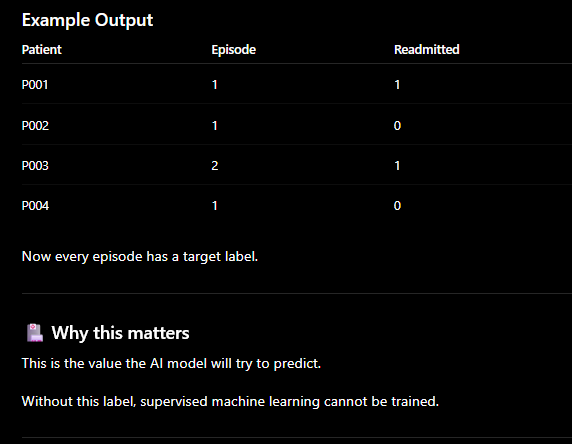

📖 What this code does

Let's count how many patients were readmitted.

In [113]:
episode_summary["readmitted"].value_counts()

,count
readmitted,
0,221


This output shows that for all 221 patient episodes, the readmitted column has a value of 0. This means that, based on the 30-day prediction window you've defined, none of the patients in your dataset were identified as being readmitted.

Part 2 — Section 16: Feature Engineering

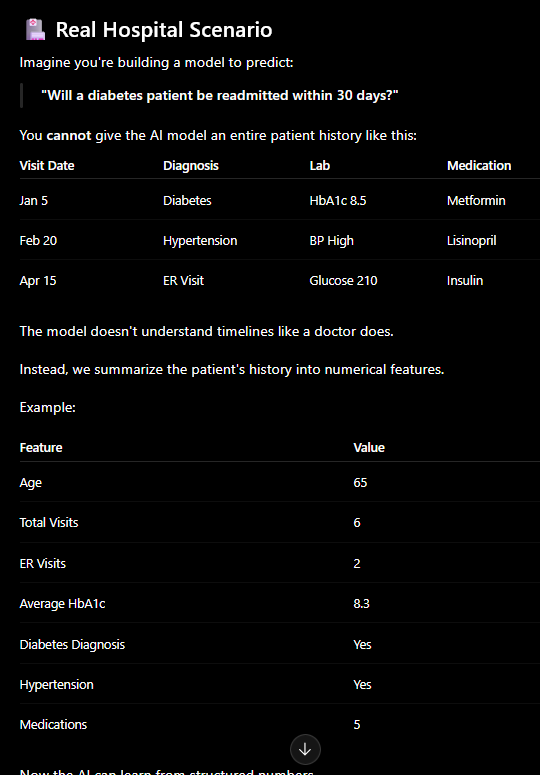

What is Feature Engineering?

Feature Engineering is the process of converting raw healthcare data into meaningful variables (features) that can be used for dashboards and machine learning.

Think of it as:

Raw EHR Data
      ↓
Patient History
      ↓
Summarize Important Information
      ↓
Machine Learning Features

What this section does

We will create several useful features:

Total visits
Number of emergency visits
Number of diagnoses
Number of medications
Average HbA1c
Chronic disease count

These are common features used in healthcare AI.

Step 1 — Count Total Visits
📖 What this code does

Count how many visits each patient had during the lookback window.

Frequent hospital visits often indicate higher healthcare needs.

In [114]:
visit_features = (
    lookback_df
    .groupby(["patient_id", "episode_number"])
    .agg(total_visits=("visit_id", "count"))
    .reset_index()
)

visit_features.head()

,patient_id,episode_number,total_visits
0,P001,1,6
1,P002,1,22
2,P003,1,8
3,P003,2,18
4,P003,3,2


visit_features = (
    lookback_df
    .groupby(["patient_id", "episode_number"])
    .agg(total_visits=("visit_id", "count"))
    .reset_index()
)

visit_features.head()

Step 2 — Count Emergency Visits

What this code does

We'll count only Emergency Department (ED) visits.

Emergency visits are strong indicators of disease severity.

In [117]:
er_features = (
    lookback_df[lookback_df["admission_type"] == "Emergency"]
    .groupby(["patient_id", "episode_number"])
    .agg(er_visits=("visit_id", "count"))
    .reset_index()
)

er_features.head()

,patient_id,episode_number,er_visits
0,P001,1,6
1,P002,1,3
2,P003,2,10
3,P004,1,15
4,P006,1,5


### Step 3 — Count Diagnoses

📖 **What this code does**

We'll count the number of unique diagnoses for each patient within their episodes during the lookback period.

Patients with multiple diagnoses might have more complex health needs.

In [118]:
diagnosis_features = (
    lookback_df
    .groupby(["patient_id", "episode_number"])
    .agg(num_diagnoses=("diagnosis", "nunique"))
    .reset_index()
)

diagnosis_features.head()

,patient_id,episode_number,num_diagnoses
0,P001,1,1
1,P002,1,4
2,P003,1,1
3,P003,2,3
4,P003,3,1


### Step 4 — Count Medications

📖 **What this code does**

We'll count the number of unique medications prescribed for each patient within their episodes during the lookback period.

The number of medications can indicate the complexity of a patient's treatment regimen.

In [119]:
medication_features = (
    lookback_df
    .groupby(["patient_id", "episode_number"])
    .agg(num_medications=("medication", "nunique"))
    .reset_index()
)

medication_features.head()

,patient_id,episode_number,num_medications
0,P001,1,3
1,P002,1,5
2,P003,1,2
3,P003,2,4
4,P003,3,1


### Step 5 — Average HbA1c

📖 **What this code does**

We'll calculate the average HbA1c level for each patient episode during the lookback period.

HbA1c is a key indicator for diabetes management, and its average can reflect long-term blood sugar control.

In [120]:
hba1c_features = (
    lookback_df[lookback_df["test_name"] == "HbA1c"]
    .groupby(["patient_id", "episode_number"])
    .agg(avg_hba1c=("result", "mean"))
    .reset_index()
)

hba1c_features.head()

,patient_id,episode_number,avg_hba1c
0,P001,1,10.0100
1,P002,1,6.9380
2,P003,1,6.0000
3,P003,2,7.0325
4,P004,1,6.9900


### Step 6 — Chronic Disease Count

📖 **What this code does**

We'll count the number of unique chronic diagnoses for each patient episode within the lookback period.

Patients with multiple chronic conditions often have higher healthcare utilization and costs.

In [121]:
chronic_diseases = [
    "Type 2 Diabetes",
    "Hypertension",
    "Heart Failure",
    "COPD",
    "Asthma",
    "Kidney Disease"
]

chronic_features = (
    lookback_df[lookback_df["diagnosis"].isin(chronic_diseases)]
    .groupby(["patient_id", "episode_number"])
    .agg(chronic_disease_count=("diagnosis", "nunique"))
    .reset_index()
)

chronic_features.head()

,patient_id,episode_number,chronic_disease_count
0,P001,1,1
1,P002,1,3
2,P003,1,1
3,P003,2,2
4,P003,3,1


### Step 7 — Combine All Features

📖 **What this code does**

We will now merge all the individual feature DataFrames (`visit_features`, `er_features`, `diagnosis_features`, `medication_features`, `hba1c_features`, `chronic_features`) into a single DataFrame, using `patient_id` and `episode_number` as the keys. This creates a comprehensive feature set for each episode of care.

In [122]:
master_features = episode_summary[["patient_id", "episode_number", "readmitted"]]

master_features = pd.merge(
    master_features,
    visit_features,
    on=["patient_id", "episode_number"],
    how="left"
)

master_features = pd.merge(
    master_features,
    er_features,
    on=["patient_id", "episode_number"],
    how="left"
).fillna(0) # Fill NaN for episodes with no ER visits

master_features = pd.merge(
    master_features,
    diagnosis_features,
    on=["patient_id", "episode_number"],
    how="left"
)

master_features = pd.merge(
    master_features,
    medication_features,
    on=["patient_id", "episode_number"],
    how="left"
)

master_features = pd.merge(
    master_features,
    hba1c_features,
    on=["patient_id", "episode_number"],
    how="left"
).fillna(0) # Fill NaN for episodes with no HbA1c tests

master_features = pd.merge(
    master_features,
    chronic_features,
    on=["patient_id", "episode_number"],
    how="left"
).fillna(0) # Fill NaN for episodes with no chronic diagnoses


master_features.head()

,patient_id,episode_number,readmitted,total_visits,er_visits,num_diagnoses,num_medications,avg_hba1c,chronic_disease_count
0,P001,1,0,6,6.0,1,3,10.0100,1.0
1,P002,1,0,22,3.0,4,5,6.9380,3.0
2,P003,1,0,8,0.0,1,2,6.0000,1.0
3,P003,2,0,18,10.0,3,4,7.0325,2.0
4,P003,3,0,2,0.0,1,1,0.0000,1.0


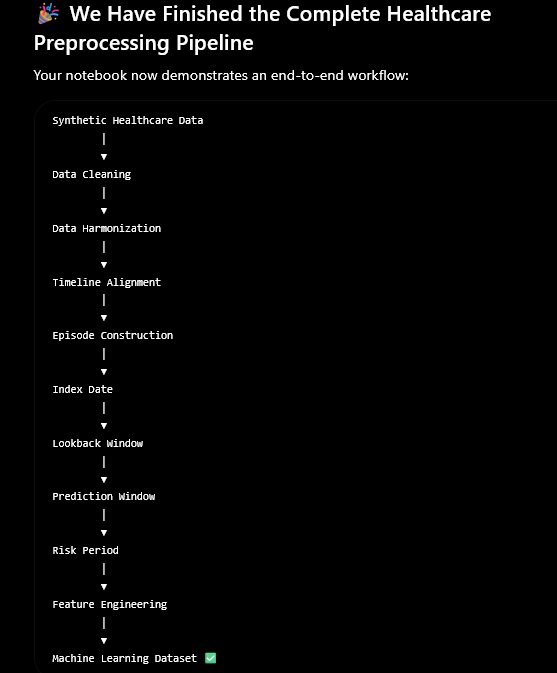